In [52]:
import tensorflow as tf

print("TensorFlow Version:", tf.__version__)

print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [53]:
import os

input_path = "/kaggle/input"

print("Available Datasets:")

for item in os.listdir(input_path):
    print(item)

Available Datasets:
datasets


In [54]:
import os

dataset_path = "/kaggle/input/datasets/karagwaanntreasure/plant-disease-detection/Dataset"

classes = os.listdir(dataset_path)

total_images = 0

for class_name in classes:
    class_path = os.path.join(dataset_path, class_name)

    if os.path.isdir(class_path):
        images = [
            f for f in os.listdir(class_path)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ]
        total_images += len(images)

print("Total Classes:", len(classes))
print("Total Images:", total_images)

Total Classes: 23
Total Images: 35725


In [55]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split

dataset_path = "/kaggle/input/datasets/karagwaanntreasure/plant-disease-detection/Dataset"

data = []

for class_name in sorted(os.listdir(dataset_path)):
    class_path = os.path.join(dataset_path, class_name)

    for img in os.listdir(class_path):
        if img.lower().endswith(('.jpg', '.jpeg', '.png')):
            data.append({
                'image_path': os.path.join(class_path, img),
                'label': class_name
            })

df = pd.DataFrame(data)

train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df['label'], random_state=42
)

val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df['label'], random_state=42
)

train_df.to_csv('/kaggle/working/train.csv', index=False)
val_df.to_csv('/kaggle/working/validation.csv', index=False)
test_df.to_csv('/kaggle/working/test.csv', index=False)

print("Training Images:", len(train_df))
print("Validation Images:", len(val_df))
print("Testing Images:", len(test_df))
print("Total Images:", len(df))
print("All CSV Files Saved Successfully!")

Training Images: 25007
Validation Images: 5359
Testing Images: 5359
Total Images: 35725
All CSV Files Saved Successfully!


TensorFlow Version: 2.21.0
GPU Devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]

========== PROJECT INFORMATION ==========
Dataset Path: /kaggle/input/datasets/karagwaanntreasure/plant-disease-detection/Dataset
Total Classes: 23
Image Size: (224, 224)
Batch Size: 32
Random Seed: 42


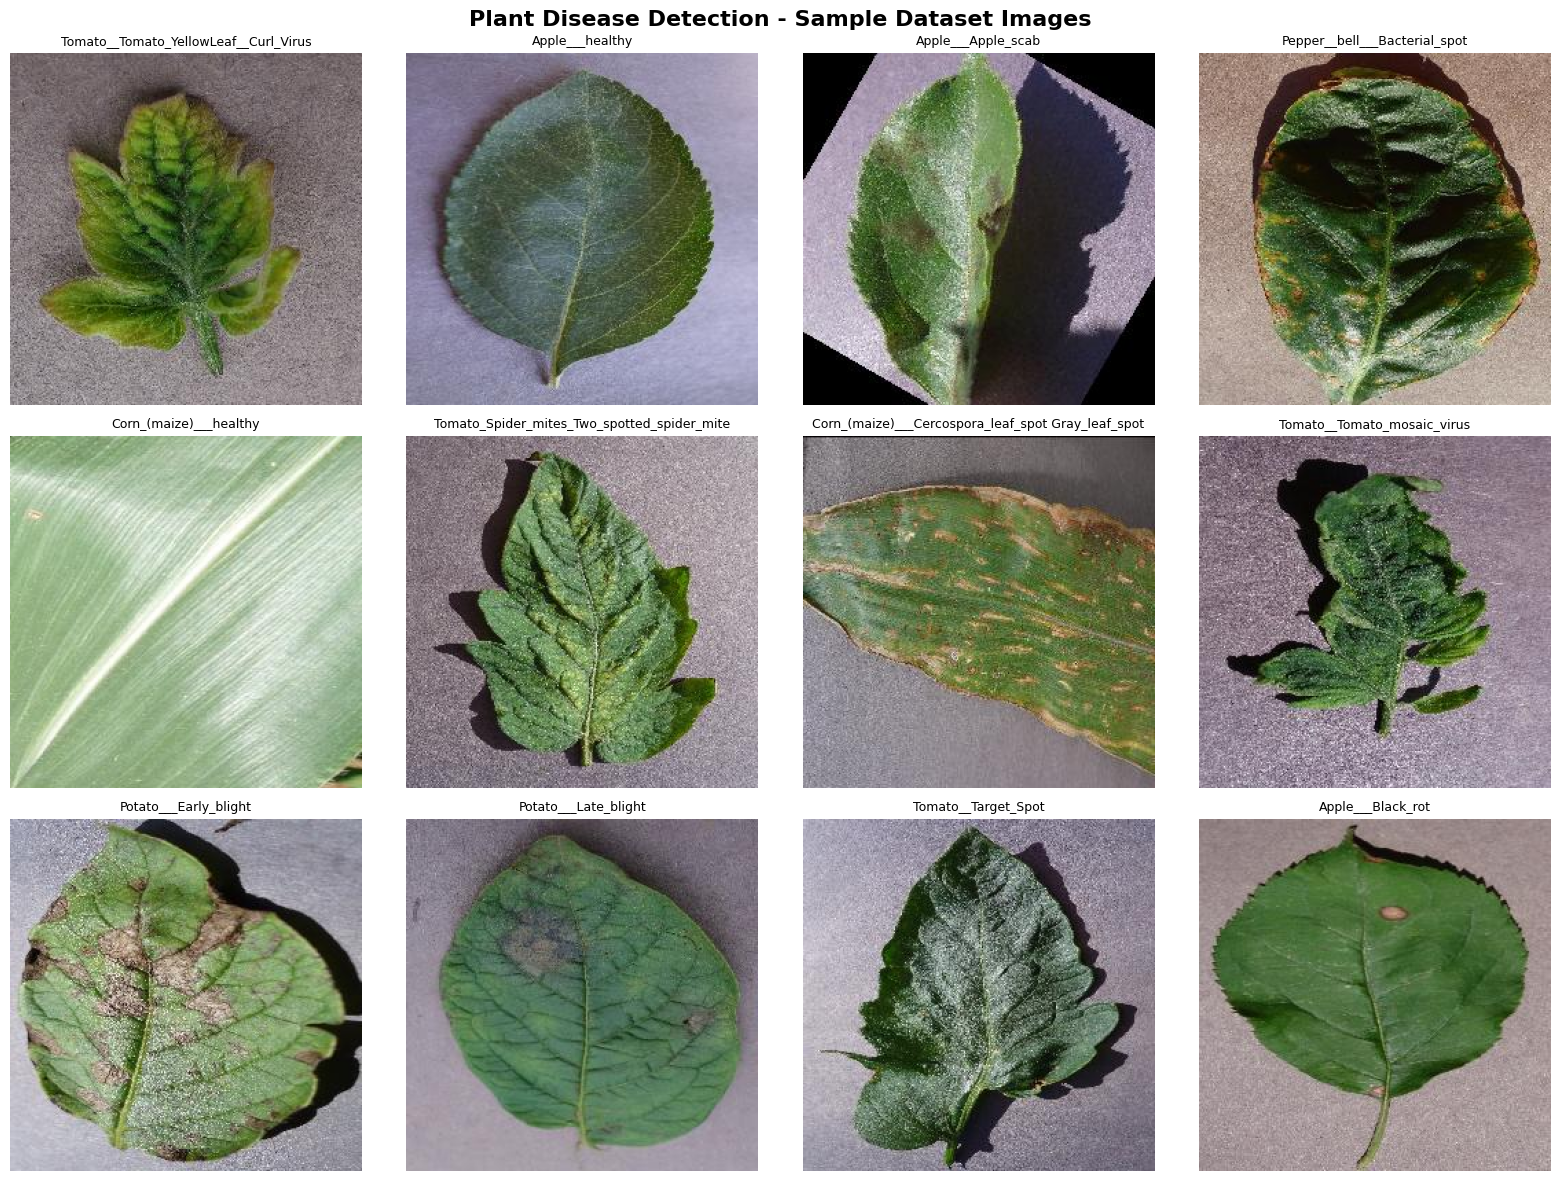


Step 01 Completed Successfully!


In [56]:
# ==========================================
# STEP 01: ENVIRONMENT SETUP
# ==========================================

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Dataset Path
DATASET_PATH = "/kaggle/input/datasets/karagwaanntreasure/plant-disease-detection/Dataset"

# Image Configuration
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 23

# GPU Configuration
print("TensorFlow Version:", tf.__version__)
print("GPU Devices:", tf.config.list_physical_devices('GPU'))

# Dataset Verification
class_names = sorted([
    name for name in os.listdir(DATASET_PATH)
    if os.path.isdir(os.path.join(DATASET_PATH, name))
])

print("\n========== PROJECT INFORMATION ==========")
print("Dataset Path:", DATASET_PATH)
print("Total Classes:", len(class_names))
print("Image Size:", IMG_SIZE)
print("Batch Size:", BATCH_SIZE)
print("Random Seed:", SEED)

# ==========================================
# DISPLAY SAMPLE IMAGES
# ==========================================

plt.figure(figsize=(16, 12))

selected_classes = random.sample(class_names, 12)

for i, class_name in enumerate(selected_classes):

    class_path = os.path.join(DATASET_PATH, class_name)

    images = [
        img for img in os.listdir(class_path)
        if img.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    image_name = random.choice(images)

    image_path = os.path.join(class_path, image_name)

    image = Image.open(image_path).convert("RGB")

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(class_name, fontsize=9)
    plt.axis("off")

plt.suptitle(
    "Plant Disease Detection - Sample Dataset Images",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

print("\nStep 01 Completed Successfully!")

========== DATASET STATISTICS ==========
Total Classes: 23
Total Images: 35725
Average Images per Class: 1553.26
Minimum Class Images: 152
Maximum Class Images: 3208

========== CLASS DISTRIBUTION ==========
                                             Class  Image_Count
             Tomato__Tomato_YellowLeaf__Curl_Virus         3208
                             Tomato_Bacterial_spot         2127
                                Apple___Apple_scab         2016
                                   Apple___healthy         2008
                                 Apple___Black_rot         1987
                                Tomato_Late_blight         1909
               Corn_(maize)___Northern_Leaf_Blight         1908
                       Corn_(maize)___Common_rust_         1907
                            Corn_(maize)___healthy         1859
                         Tomato_Septoria_leaf_spot         1771
                          Apple___Cedar_apple_rust         1760
       Tomato_Spider_mit

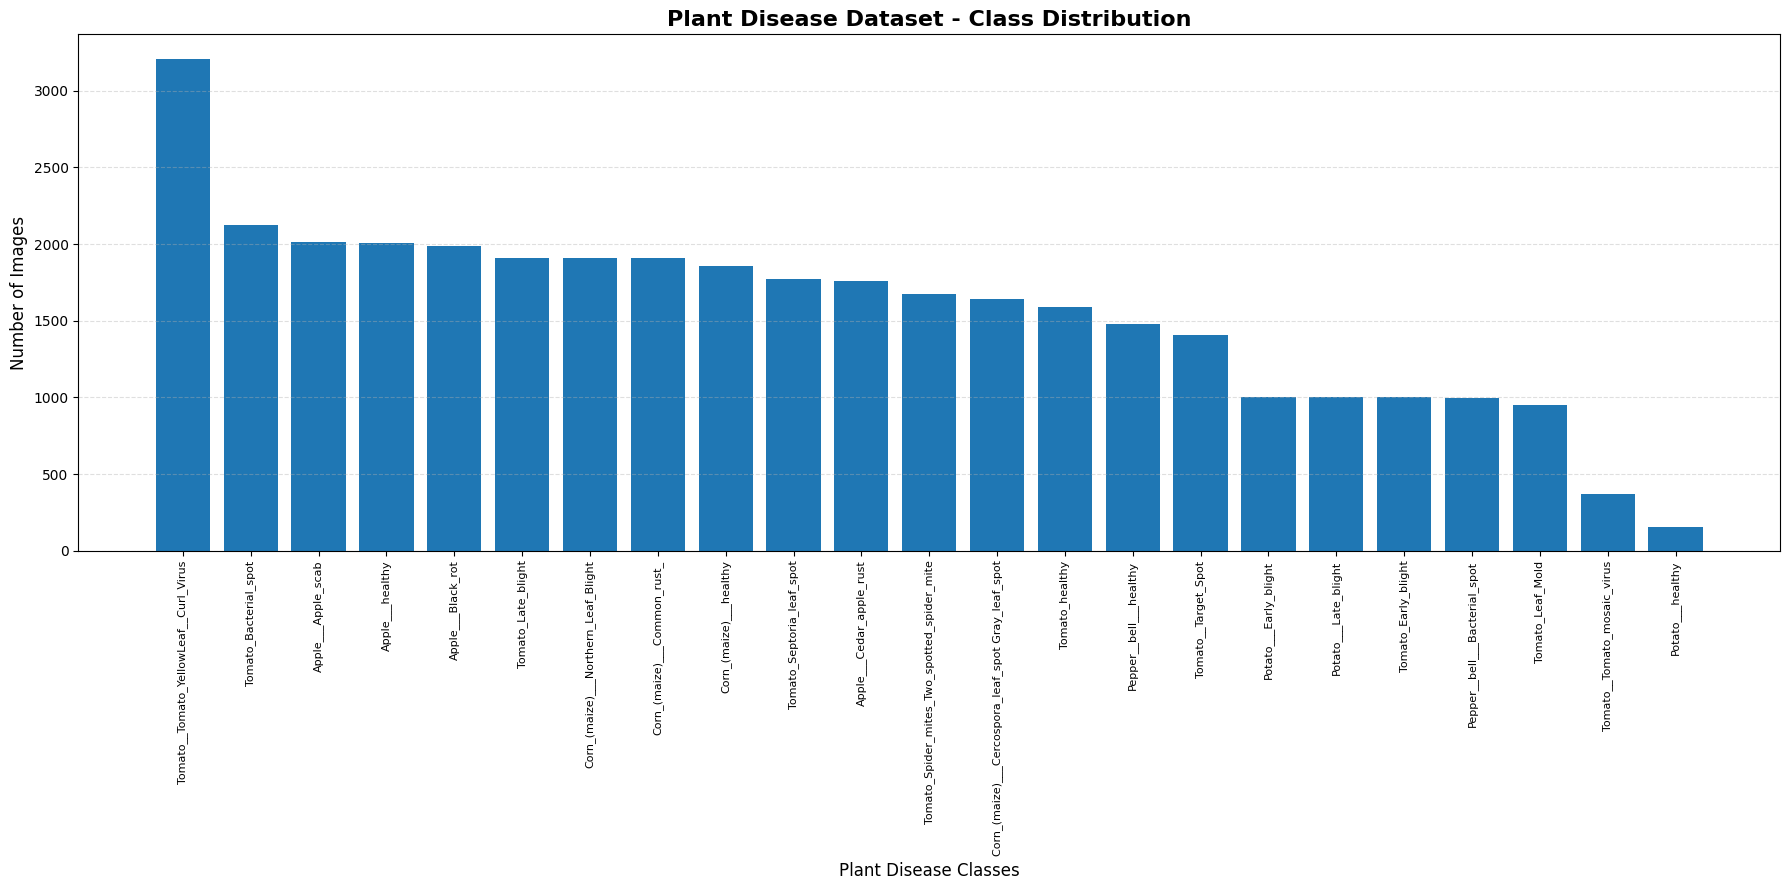


Step 02 Completed Successfully!


In [57]:
# ==========================================
# STEP 02: EXPLORATORY DATA ANALYSIS (EDA)
# CLASS DISTRIBUTION
# ==========================================

import os
import pandas as pd
import matplotlib.pyplot as plt

image_extensions = ('.jpg', '.jpeg', '.png')

class_data = []

for class_name in class_names:

    class_path = os.path.join(DATASET_PATH, class_name)

    images = [
        img for img in os.listdir(class_path)
        if img.lower().endswith(image_extensions)
    ]

    class_data.append({
        'Class': class_name,
        'Image_Count': len(images)
    })

class_df = pd.DataFrame(class_data)

# Sort by image count
class_df = class_df.sort_values(
    by='Image_Count',
    ascending=False
)

# Dataset Statistics
total_images = class_df['Image_Count'].sum()
total_classes = len(class_df)

print("========== DATASET STATISTICS ==========")
print("Total Classes:", total_classes)
print("Total Images:", total_images)
print("Average Images per Class:", round(total_images / total_classes, 2))
print("Minimum Class Images:", class_df['Image_Count'].min())
print("Maximum Class Images:", class_df['Image_Count'].max())

print("\n========== CLASS DISTRIBUTION ==========")
print(class_df.to_string(index=False))

# ==========================================
# CLASS DISTRIBUTION BAR CHART
# ==========================================

plt.figure(figsize=(18, 9))

plt.bar(
    class_df['Class'],
    class_df['Image_Count']
)

plt.title(
    "Plant Disease Dataset - Class Distribution",
    fontsize=16,
    fontweight='bold'
)

plt.xlabel("Plant Disease Classes", fontsize=12)
plt.ylabel("Number of Images", fontsize=12)

plt.xticks(rotation=90, fontsize=8)

plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

print("\nStep 02 Completed Successfully!")

========== IMBALANCE ANALYSIS ==========
Total Classes: 23
Total Images: 35725
Average Images: 1553.26
Maximum Images: 3208
Minimum Images: 152
Imbalance Ratio: 21.11
Coefficient of Variation: 41.71 %

Largest Class: Tomato__Tomato_YellowLeaf__Curl_Virus
Images: 3208

Smallest Class: Potato___healthy
Images: 152


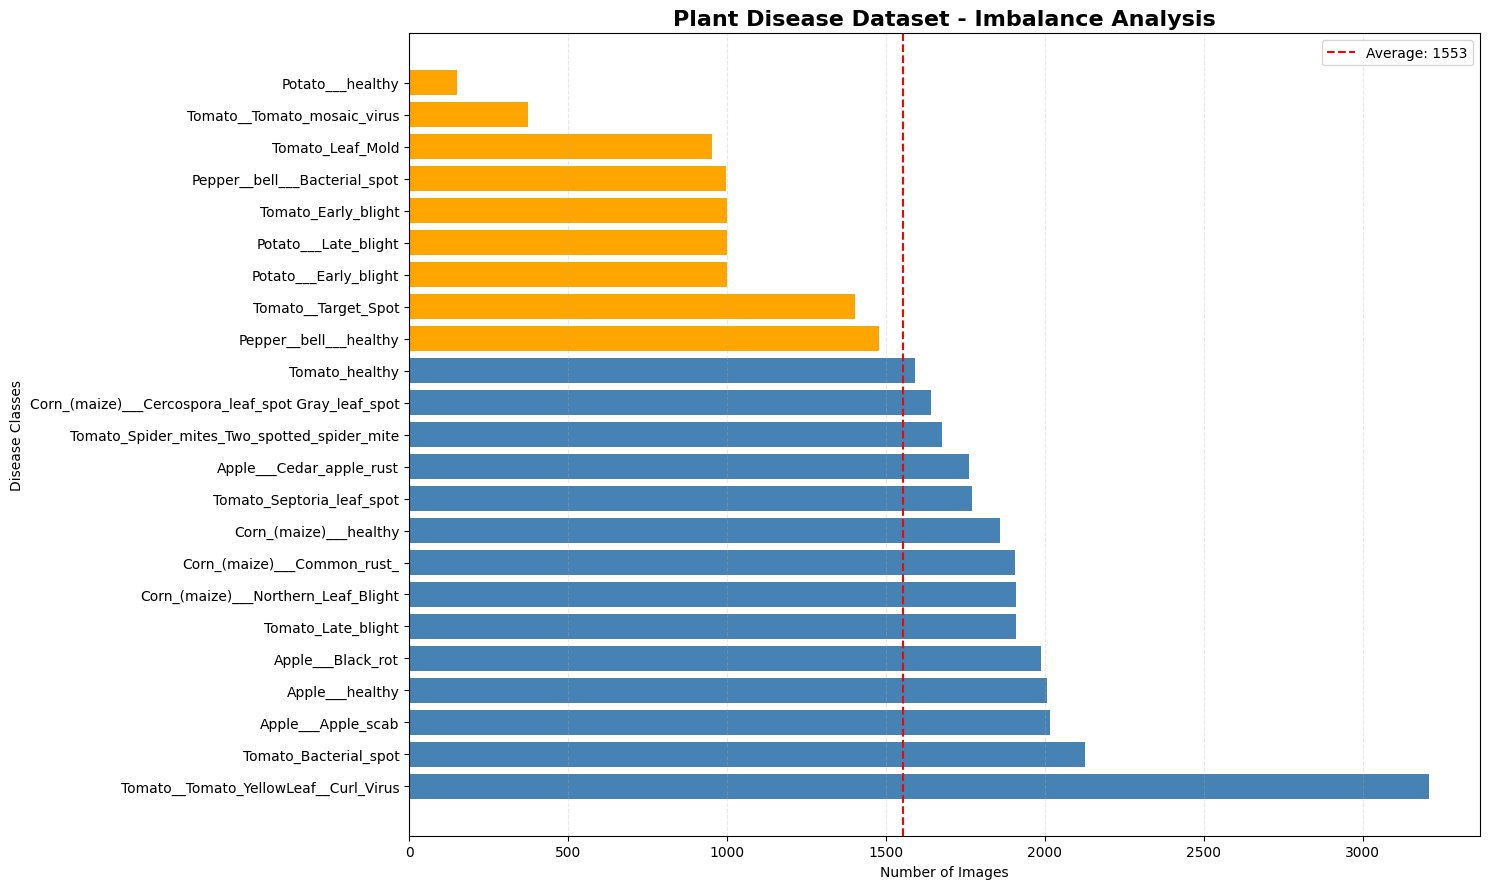


Step 03 Completed Successfully!


In [58]:
# ==========================================
# STEP 03: DATASET IMBALANCE ANALYSIS
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

# Calculate Statistics
mean_images = class_df['Image_Count'].mean()
max_images = class_df['Image_Count'].max()
min_images = class_df['Image_Count'].min()

imbalance_ratio = max_images / min_images

std_images = class_df['Image_Count'].std()
cv = (std_images / mean_images) * 100

print("========== IMBALANCE ANALYSIS ==========")

print("Total Classes:", len(class_df))
print("Total Images:", class_df['Image_Count'].sum())

print("Average Images:", round(mean_images, 2))
print("Maximum Images:", max_images)
print("Minimum Images:", min_images)

print("Imbalance Ratio:", round(imbalance_ratio, 2))
print("Coefficient of Variation:", round(cv, 2), "%")

# Identify Largest and Smallest Classes
largest_class = class_df.loc[
    class_df['Image_Count'].idxmax()
]

smallest_class = class_df.loc[
    class_df['Image_Count'].idxmin()
]

print("\nLargest Class:", largest_class['Class'])
print("Images:", largest_class['Image_Count'])

print("\nSmallest Class:", smallest_class['Class'])
print("Images:", smallest_class['Image_Count'])

# ==========================================
# IMBALANCE VISUALIZATION
# ==========================================

plt.figure(figsize=(15, 9))

colors = [
    'orange' if count < mean_images else 'steelblue'
    for count in class_df['Image_Count']
]

plt.barh(
    class_df['Class'],
    class_df['Image_Count'],
    color=colors
)

plt.axvline(
    mean_images,
    color='red',
    linestyle='--',
    label=f'Average: {mean_images:.0f}'
)

plt.title(
    'Plant Disease Dataset - Imbalance Analysis',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel("Number of Images")
plt.ylabel("Disease Classes")

plt.legend()
plt.grid(axis='x', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

print("\nStep 03 Completed Successfully!")

========== IMAGE QUALITY ANALYSIS ==========
Images Analyzed: 598

Image Width:
count    598.0
mean     256.0
std        0.0
min      256.0
25%      256.0
50%      256.0
75%      256.0
max      256.0
Name: Width, dtype: float64

Image Height:
count    598.0
mean     256.0
std        0.0
min      256.0
25%      256.0
50%      256.0
75%      256.0
max      256.0
Name: Height, dtype: float64

Image Formats:
Format
JPEG    598
Name: count, dtype: int64

Color Modes:
Mode
RGB    598
Name: count, dtype: int64

Unique Dimensions: 1


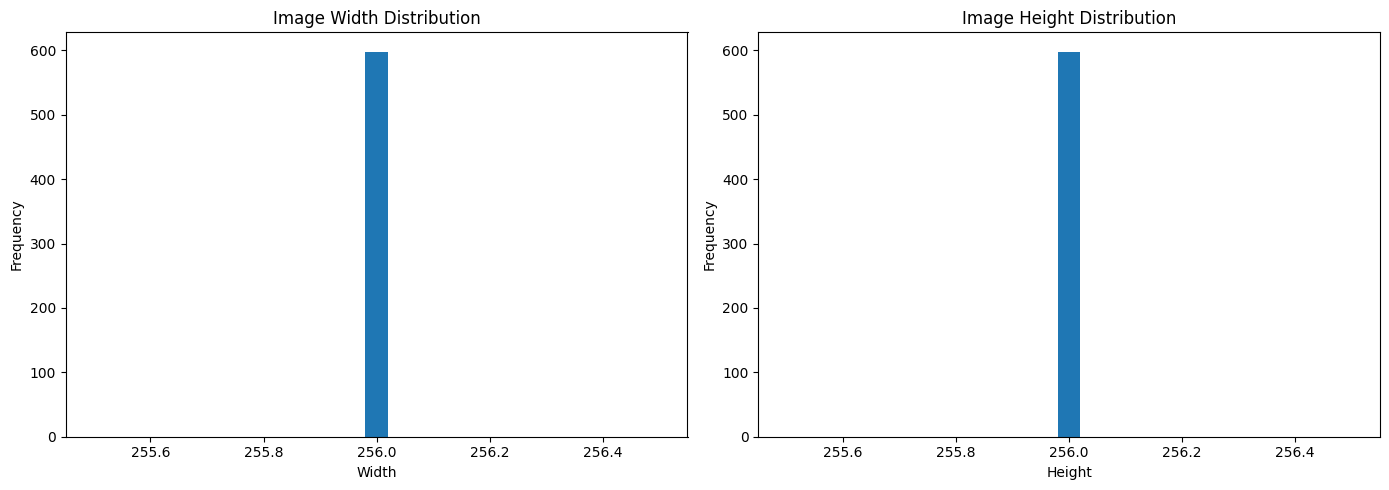

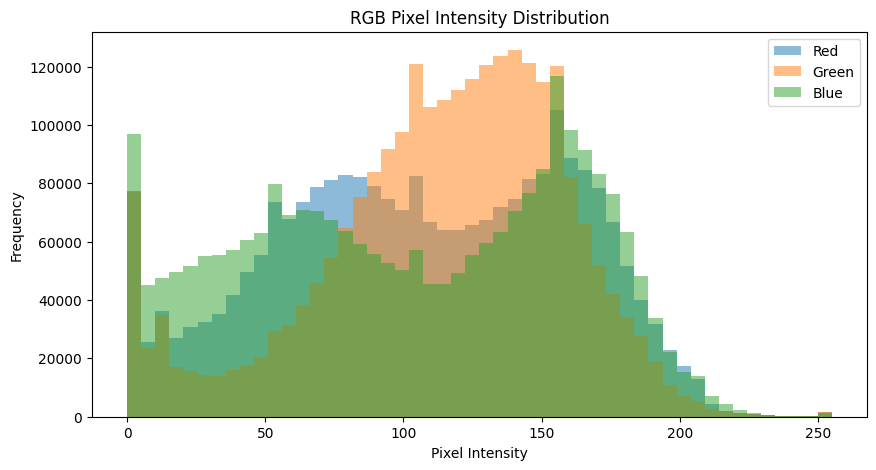


Step 04 Completed Successfully!


In [59]:
# ==========================================
# STEP 04: FAST IMAGE QUALITY ANALYSIS
# ==========================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import random

image_records = []
sample_pixels = []

MAX_SAMPLE = 500

for class_name in class_names:
    class_path = os.path.join(DATASET_PATH, class_name)

    images = [
        f for f in os.listdir(class_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    selected_images = random.sample(
        images, min(len(images), MAX_SAMPLE // NUM_CLASSES + 5)
    )

    for img_name in selected_images:
        img_path = os.path.join(class_path, img_name)

        try:
            with Image.open(img_path) as img:
                image_records.append({
                    'Class': class_name,
                    'Width': img.width,
                    'Height': img.height,
                    'Format': img.format,
                    'Mode': img.mode
                })

                if len(sample_pixels) < 50:
                    rgb_img = img.convert("RGB").resize((224, 224))
                    sample_pixels.append(np.array(rgb_img))

        except Exception as e:
            print("Error:", img_path)

image_df = pd.DataFrame(image_records)

print("========== IMAGE QUALITY ANALYSIS ==========")
print("Images Analyzed:", len(image_df))
print("\nImage Width:")
print(image_df['Width'].describe())

print("\nImage Height:")
print(image_df['Height'].describe())

print("\nImage Formats:")
print(image_df['Format'].value_counts())

print("\nColor Modes:")
print(image_df['Mode'].value_counts())

print("\nUnique Dimensions:",
      image_df.groupby(['Width', 'Height']).ngroups)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.hist(image_df['Width'], bins=25)
plt.title("Image Width Distribution")
plt.xlabel("Width")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
plt.hist(image_df['Height'], bins=25)
plt.title("Image Height Distribution")
plt.xlabel("Height")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

pixels = np.concatenate(sample_pixels).reshape(-1, 3)

plt.figure(figsize=(10, 5))

for i, color in enumerate(['Red', 'Green', 'Blue']):
    plt.hist(pixels[:, i], bins=50, alpha=0.5, label=color)

plt.title("RGB Pixel Intensity Distribution")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.legend()
plt.show()

print("\nStep 04 Completed Successfully!")

In [60]:
import os

DATASET_PATH = "/kaggle/input/datasets/karagwaanntreasure/plant-disease-detection/Dataset"

class_names = sorted([
    folder for folder in os.listdir(DATASET_PATH)
    if os.path.isdir(os.path.join(DATASET_PATH, folder))
])

NUM_CLASSES = len(class_names)
IMG_SIZE = (224, 224)

print("Total Classes:", NUM_CLASSES)
print("Class Names:", class_names)

Total Classes: 23
Class Names: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Pepper__bell___Bacterial_spot', 'Pepper__bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']


Total Sample Images: 8
Original Shape: (224, 224, 3)
Normalized Shape: (224, 224, 3)
Pixel Range: 0.007843138 to 0.8862745


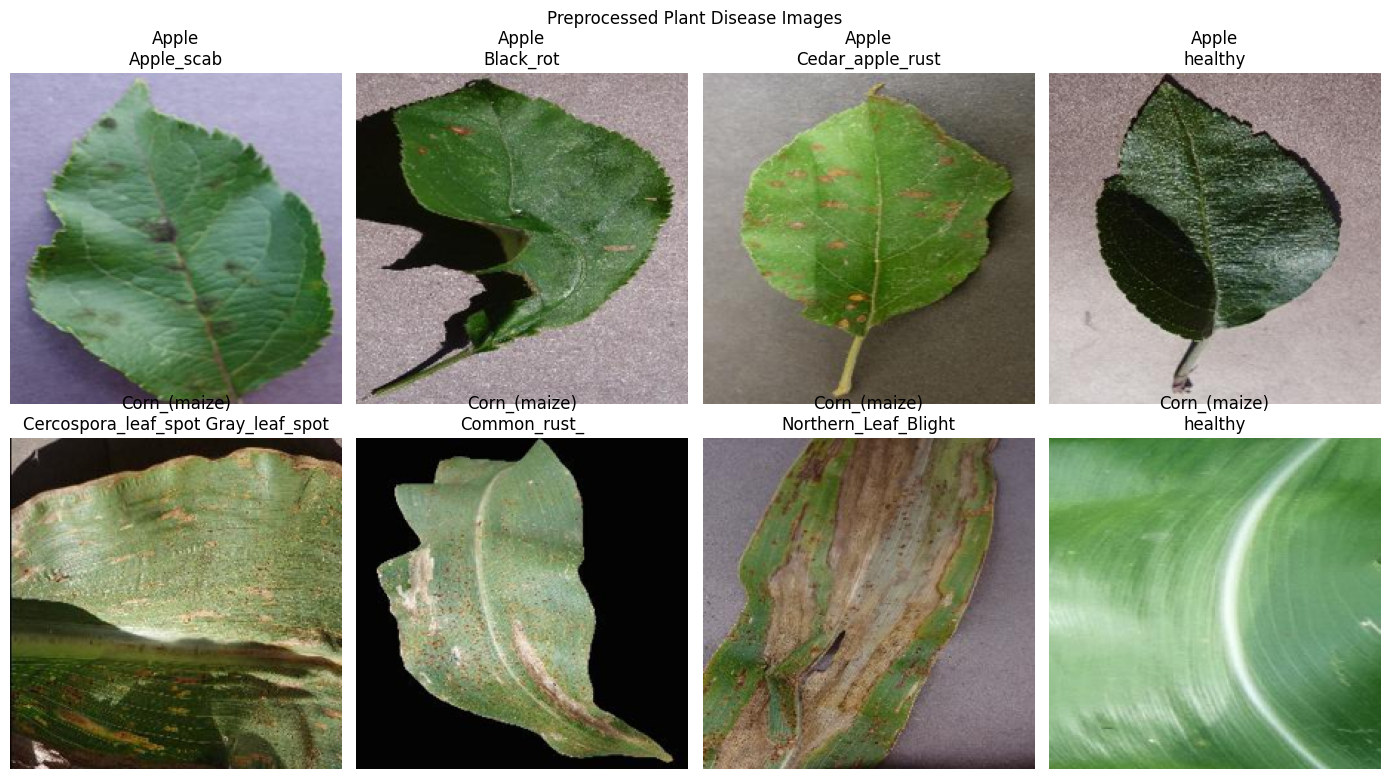

STEP 05 COMPLETED SUCCESSFULLY!


In [61]:
# ==========================================
# STEP 05: IMAGE PREPROCESSING
# ==========================================

import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

sample_images = []

for class_name in class_names[:8]:
    folder = os.path.join(DATASET_PATH, class_name)
    img_name = next(
        f for f in os.listdir(folder)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    )

    img_path = os.path.join(folder, img_name)

    img = Image.open(img_path).convert("RGB")
    img = img.resize(IMG_SIZE)

    original = np.array(img)
    normalized = original.astype("float32") / 255.0

    sample_images.append((original, normalized, class_name))

print("Total Sample Images:", len(sample_images))
print("Original Shape:", sample_images[0][0].shape)
print("Normalized Shape:", sample_images[0][1].shape)
print("Pixel Range:",
      sample_images[0][1].min(),
      "to",
      sample_images[0][1].max())

plt.figure(figsize=(14, 8))

for i, (original, normalized, name) in enumerate(sample_images):
    plt.subplot(2, 4, i+1)
    plt.imshow(normalized)
    plt.title(name.replace("___", "\n"))
    plt.axis("off")

plt.suptitle("Preprocessed Plant Disease Images")
plt.tight_layout()
plt.show()

print("STEP 05 COMPLETED SUCCESSFULLY!")

In [62]:
# ==========================================
# STEP 06: DATASET SPLITTING
# ==========================================

import os
import pandas as pd
from sklearn.model_selection import train_test_split

image_paths = []
labels = []

for class_name in class_names:
    folder = os.path.join(DATASET_PATH, class_name)

    for img in os.listdir(folder):
        if img.lower().endswith(('.jpg', '.jpeg', '.png')):
            image_paths.append(os.path.join(folder, img))
            labels.append(class_name)

df = pd.DataFrame({
    "image_path": image_paths,
    "label": labels
})

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

print("Total Images:", len(df))
print("Training Images:", len(train_df))
print("Validation Images:", len(val_df))
print("Testing Images:", len(test_df))

print("\nClass Count:", df["label"].nunique())

print("\nSTEP 06 COMPLETED SUCCESSFULLY!")

Total Images: 35725
Training Images: 25007
Validation Images: 5359
Testing Images: 5359

Class Count: 23

STEP 06 COMPLETED SUCCESSFULLY!


DATASET DISTRIBUTION:


,Training,Validation,Testing
label,,,
Apple___Apple_scab,1411,303,302
Apple___Black_rot,1391,298,298
Apple___Cedar_apple_rust,1232,264,264
Apple___healthy,1406,301,301
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,1149,247,246
Corn_(maize)___Common_rust_,1335,286,286
Corn_(maize)___Northern_Leaf_Blight,1336,286,286
Corn_(maize)___healthy,1301,279,279
Pepper__bell___Bacterial_spot,698,150,149


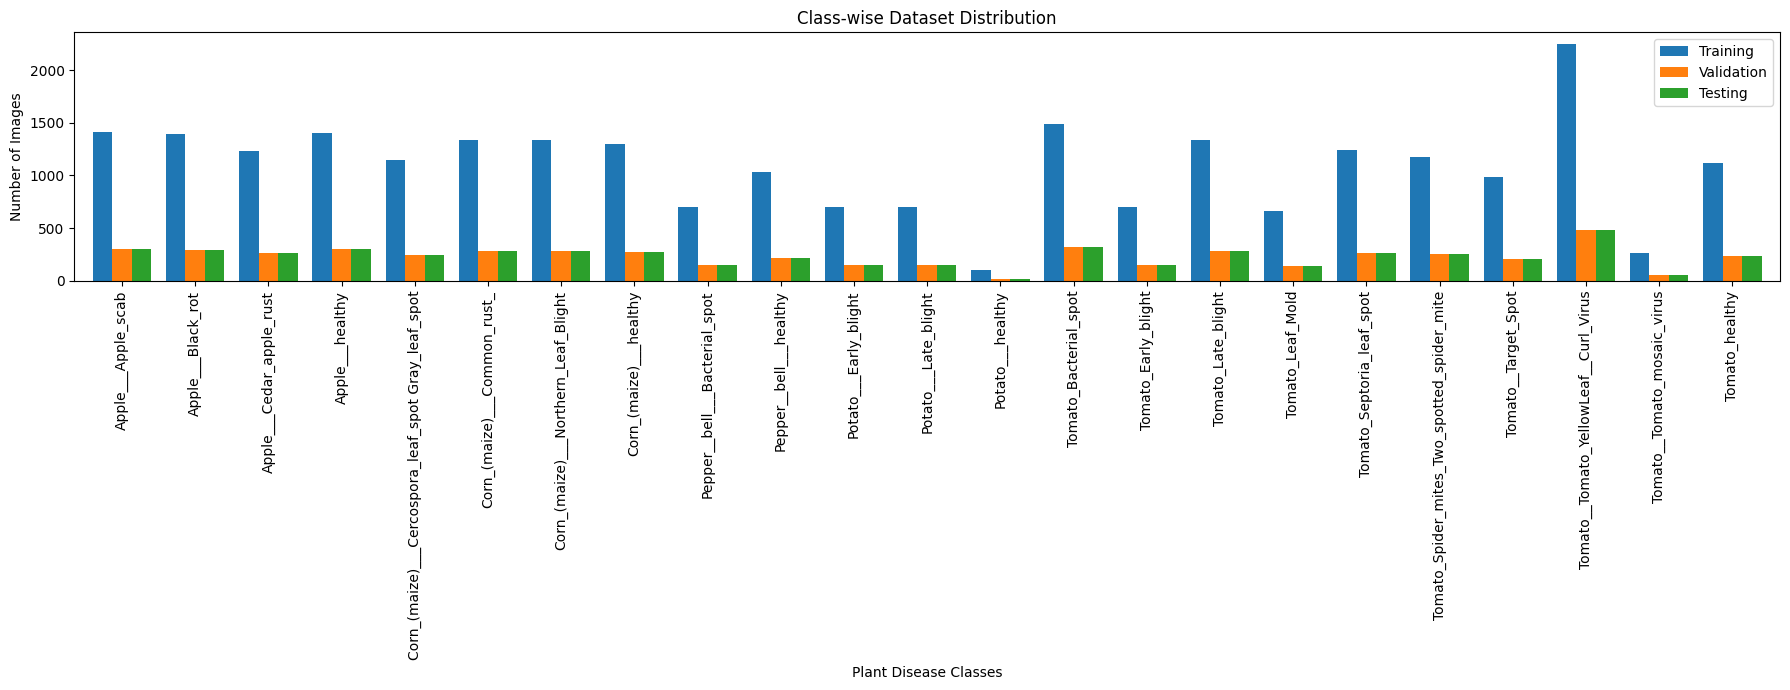

STEP 07 COMPLETED SUCCESSFULLY!


In [63]:
# ==========================================
# STEP 07: DATASET DISTRIBUTION
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt

split_df = pd.DataFrame({
    "Training": train_df["label"].value_counts(),
    "Validation": val_df["label"].value_counts(),
    "Testing": test_df["label"].value_counts()
}).fillna(0).astype(int)

print("DATASET DISTRIBUTION:")
display(split_df)

split_df.plot(
    kind="bar",
    figsize=(18, 7),
    width=0.8
)

plt.title("Class-wise Dataset Distribution")
plt.xlabel("Plant Disease Classes")
plt.ylabel("Number of Images")
plt.xticks(rotation=90)
plt.legend()
plt.tight_layout()
plt.show()

print("STEP 07 COMPLETED SUCCESSFULLY!")

In [64]:
# ==========================================
# STEP 08: TENSORFLOW DATA PIPELINE
# ==========================================

import tensorflow as tf
import numpy as np

BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

label_to_index = {
    name: index for index, name in enumerate(class_names)
}

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(
        image, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)

    return image, label

def create_dataset(dataframe, training=False):
    paths = dataframe["image_path"].values
    labels = dataframe["label"].map(label_to_index).values

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        dataset = dataset.shuffle(
            buffer_size=5000,
            seed=42
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset

train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

images, labels = next(iter(train_ds))

print("Training Batch Shape:", images.shape)
print("Label Batch Shape:", labels.shape)
print("Image Pixel Range:", images.numpy().min(), "to", images.numpy().max())
print("Training Batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation Batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Testing Batches:", tf.data.experimental.cardinality(test_ds).numpy())

print("\nSTEP 08 COMPLETED SUCCESSFULLY!")

Training Batch Shape: (32, 224, 224, 3)
Label Batch Shape: (32,)
Image Pixel Range: 0.0 to 255.0
Training Batches: 782
Validation Batches: 168
Testing Batches: 168

STEP 08 COMPLETED SUCCESSFULLY!


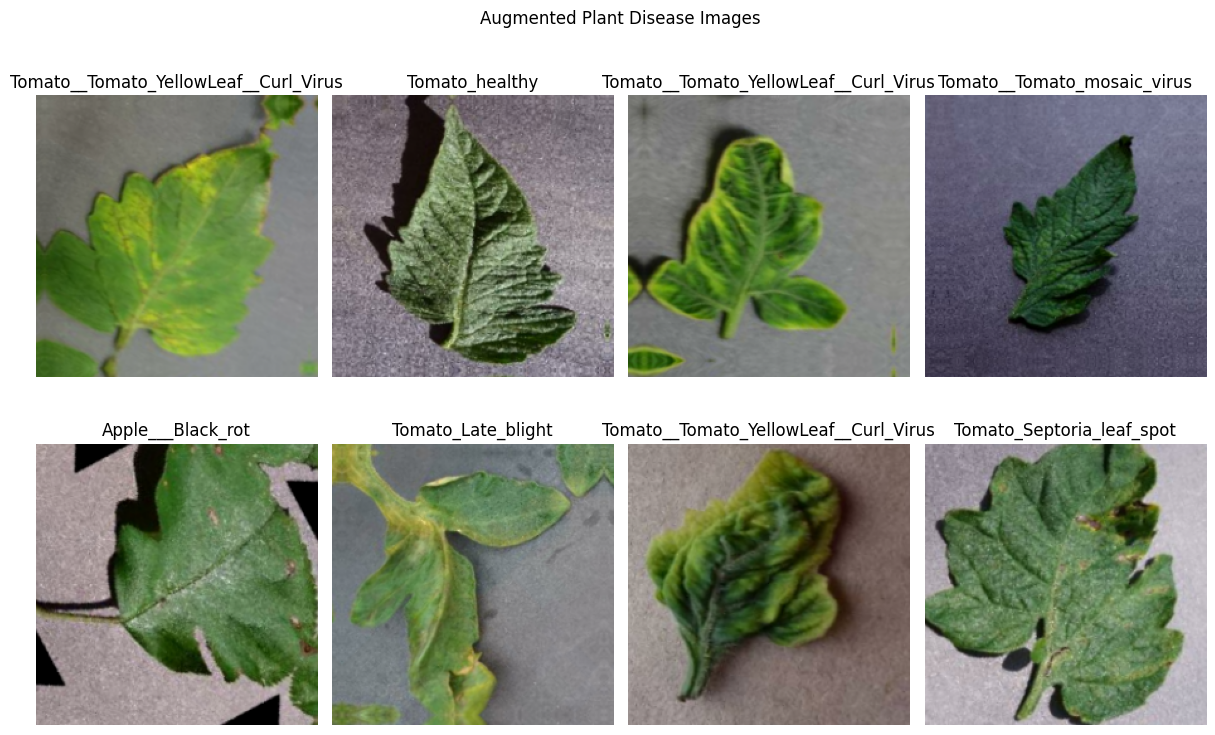

STEP 09 COMPLETED SUCCESSFULLY!


In [65]:
# ==========================================
# STEP 09: DATA AUGMENTATION
# ==========================================

import tensorflow as tf
import matplotlib.pyplot as plt

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.15),
    tf.keras.layers.RandomZoom(0.15),
    tf.keras.layers.RandomContrast(0.1)
])

images, labels = next(iter(train_ds))

plt.figure(figsize=(12, 8))

for i in range(8):
    augmented_image = data_augmentation(
        images[i:i+1], training=True
    )

    plt.subplot(2, 4, i+1)
    plt.imshow(tf.cast(augmented_image[0], tf.uint8))
    plt.title(class_names[int(labels[i])])
    plt.axis("off")

plt.suptitle("Augmented Plant Disease Images")
plt.tight_layout()
plt.show()

print("STEP 09 COMPLETED SUCCESSFULLY!")

In [66]:
# ==========================================
# STEP 10: TRAINING CONFIGURATION
# ==========================================

import tensorflow as tf
import os

EPOCHS = 10
LEARNING_RATE = 0.0001
NUM_CLASSES = len(class_names)

MODEL_DIR = "/kaggle/working/Trained_Models"
os.makedirs(MODEL_DIR, exist_ok=True)

print("========== TRAINING CONFIGURATION ==========")

print("GPU Devices:", tf.config.list_physical_devices("GPU"))
print("Image Size:", IMG_SIZE)
print("Batch Size:", BATCH_SIZE)
print("Number of Classes:", NUM_CLASSES)
print("Epochs:", EPOCHS)
print("Learning Rate:", LEARNING_RATE)

print("\nSelected Models:")
print("1. Custom CNN")
print("2. MobileNetV2")
print("3. ResNet50")
print("4. EfficientNetB0")

print("\nModel Save Directory:", MODEL_DIR)

print("\nSTEP 10 COMPLETED SUCCESSFULLY!")

========== TRAINING CONFIGURATION ==========
GPU Devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Image Size: (224, 224)
Batch Size: 32
Number of Classes: 23
Epochs: 10
Learning Rate: 0.0001

Selected Models:
1. Custom CNN
2. MobileNetV2
3. ResNet50
4. EfficientNetB0

Model Save Directory: /kaggle/working/Trained_Models

STEP 10 COMPLETED SUCCESSFULLY!


In [67]:
# ==========================================
# STEP 11: CUSTOM CNN MODEL
# ==========================================

import tensorflow as tf

def build_custom_cnn():

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(224, 224, 3)),

        tf.keras.layers.Rescaling(1./255),

        tf.keras.layers.Conv2D(32, (3,3), activation='relu', padding='same'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.MaxPooling2D(2,2),

        tf.keras.layers.Conv2D(64, (3,3), activation='relu', padding='same'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.MaxPooling2D(2,2),

        tf.keras.layers.Conv2D(128, (3,3), activation='relu', padding='same'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.MaxPooling2D(2,2),

        tf.keras.layers.Conv2D(256, (3,3), activation='relu', padding='same'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.MaxPooling2D(2,2),

        tf.keras.layers.GlobalAveragePooling2D(),

        tf.keras.layers.Dense(256, activation='relu'),
        tf.keras.layers.Dropout(0.5),

        tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')
    ])

    return model

custom_cnn = build_custom_cnn()

custom_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

custom_cnn.summary()

print("STEP 11 COMPLETED SUCCESSFULLY!")

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_4 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 23)             │         5,911 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 462,039 (1.76 MB)

 Trainable params: 461,079 (1.76 MB)

 Non-trainable params: 960 (3.75 KB)

STEP 11 COMPLETED SUCCESSFULLY!


In [68]:
# ==========================================
# STEP 12: TRAINING CALLBACKS
# ==========================================

callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=f"{MODEL_DIR}/custom_cnn_best.keras",
        monitor="val_loss",
        save_best_only=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7
    ),

    tf.keras.callbacks.CSVLogger(
        f"{MODEL_DIR}/custom_cnn_training.csv"
    )
]

print("Total Callbacks:", len(callbacks))
print("Early Stopping: Ready")
print("Model Checkpoint: Ready")
print("Learning Rate Scheduler: Ready")
print("CSV Logger: Ready")

print("\nSTEP 12 COMPLETED SUCCESSFULLY!")

Total Callbacks: 4
Early Stopping: Ready
Model Checkpoint: Ready
Learning Rate Scheduler: Ready
CSV Logger: Ready

STEP 12 COMPLETED SUCCESSFULLY!


In [69]:
# ==========================================
# STEP 13: CUSTOM CNN TRAINING
# ==========================================

history_cnn = custom_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

print("\nCUSTOM CNN TRAINING COMPLETED!")

Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 70s 81ms/step - accuracy: 0.5938 - loss: 1.3865 - val_accuracy: 0.7414 - val_loss: 0.8679 - learning_rate: 1.0000e-04
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 60s 77ms/step - accuracy: 0.7829 - loss: 0.7149 - val_accuracy: 0.8793 - val_loss: 0.4199 - learning_rate: 1.0000e-04
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 60s 76ms/step - accuracy: 0.8401 - loss: 0.5204 - val_accuracy: 0.8809 - val_loss: 0.3670 - learning_rate: 1.0000e-04
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 59s 76ms/step - accuracy: 0.8754 - loss: 0.4090 - val_accuracy: 0.9233 - val_loss: 0.2611 - learning_rate: 1.0000e-04
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 60s 76ms/step - accuracy: 0.9011 - loss: 0.3278 - val_accuracy: 0.9403 - val_loss: 0.2040 - learning_rate: 1.0000e-04
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 59s 76ms/step - accuracy: 0.9151 - loss: 0.2773 - val_accuracy: 0.9431 - val_loss: 0.1801 - learning_rate: 1.0000e-04
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 59s 76ms/ste

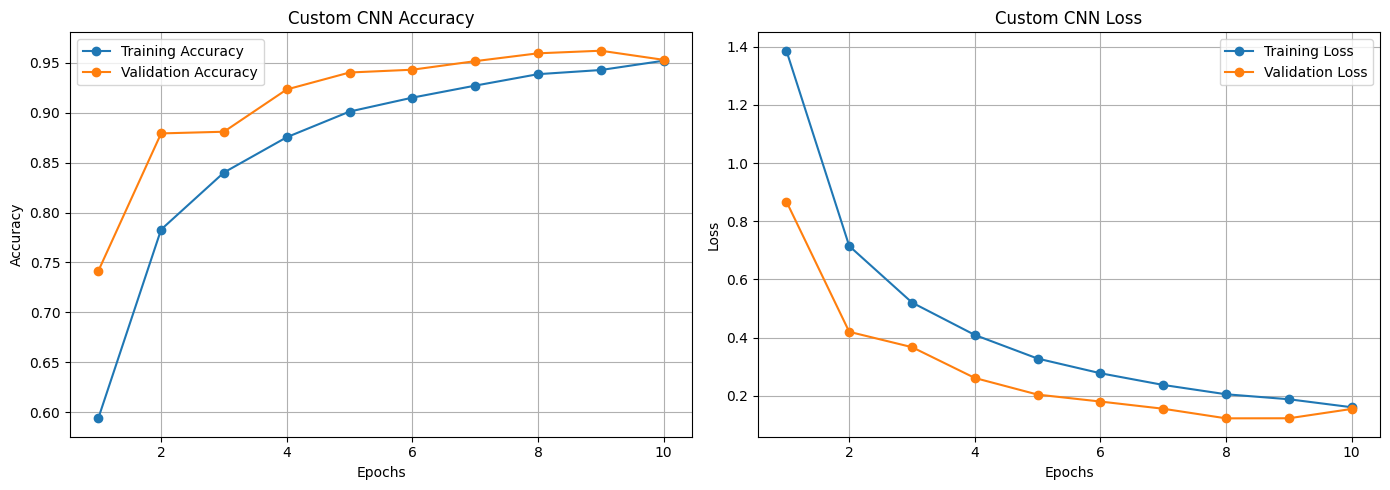

STEP 14 COMPLETED SUCCESSFULLY!


In [70]:
# ==========================================
# STEP 14: CNN TRAINING GRAPHS
# ==========================================

import matplotlib.pyplot as plt

history = history_cnn.history
epochs_range = range(1, len(history['accuracy']) + 1)

plt.figure(figsize=(14, 5))

# Accuracy Graph
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history['accuracy'], marker='o', label='Training Accuracy')
plt.plot(epochs_range, history['val_accuracy'], marker='o', label='Validation Accuracy')
plt.title('Custom CNN Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Loss Graph
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history['loss'], marker='o', label='Training Loss')
plt.plot(epochs_range, history['val_loss'], marker='o', label='Validation Loss')
plt.title('Custom CNN Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig(f"{MODEL_DIR}/custom_cnn_training_graphs.png", dpi=300)
plt.show()

print("STEP 14 COMPLETED SUCCESSFULLY!")

168/168 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step
========== CUSTOM CNN TEST RESULTS ==========
Test Accuracy: 95.8 %
Precision: 0.9592
Recall: 0.958
F1-Score: 0.9575

Classification Report:
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.99      0.98      0.98       302
                                 Apple___Black_rot       0.99      0.99      0.99       298
                          Apple___Cedar_apple_rust       1.00      0.99      0.99       264
                                   Apple___healthy       0.99      0.99      0.99       301
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.96      0.92      0.94       246
                       Corn_(maize)___Common_rust_       1.00      0.98      0.99       286
               Corn_(maize)___Northern_Leaf_Blight       0.94      0.97      0.95       286
                            Corn_(maize)___healthy       1.00      1.00      1.0

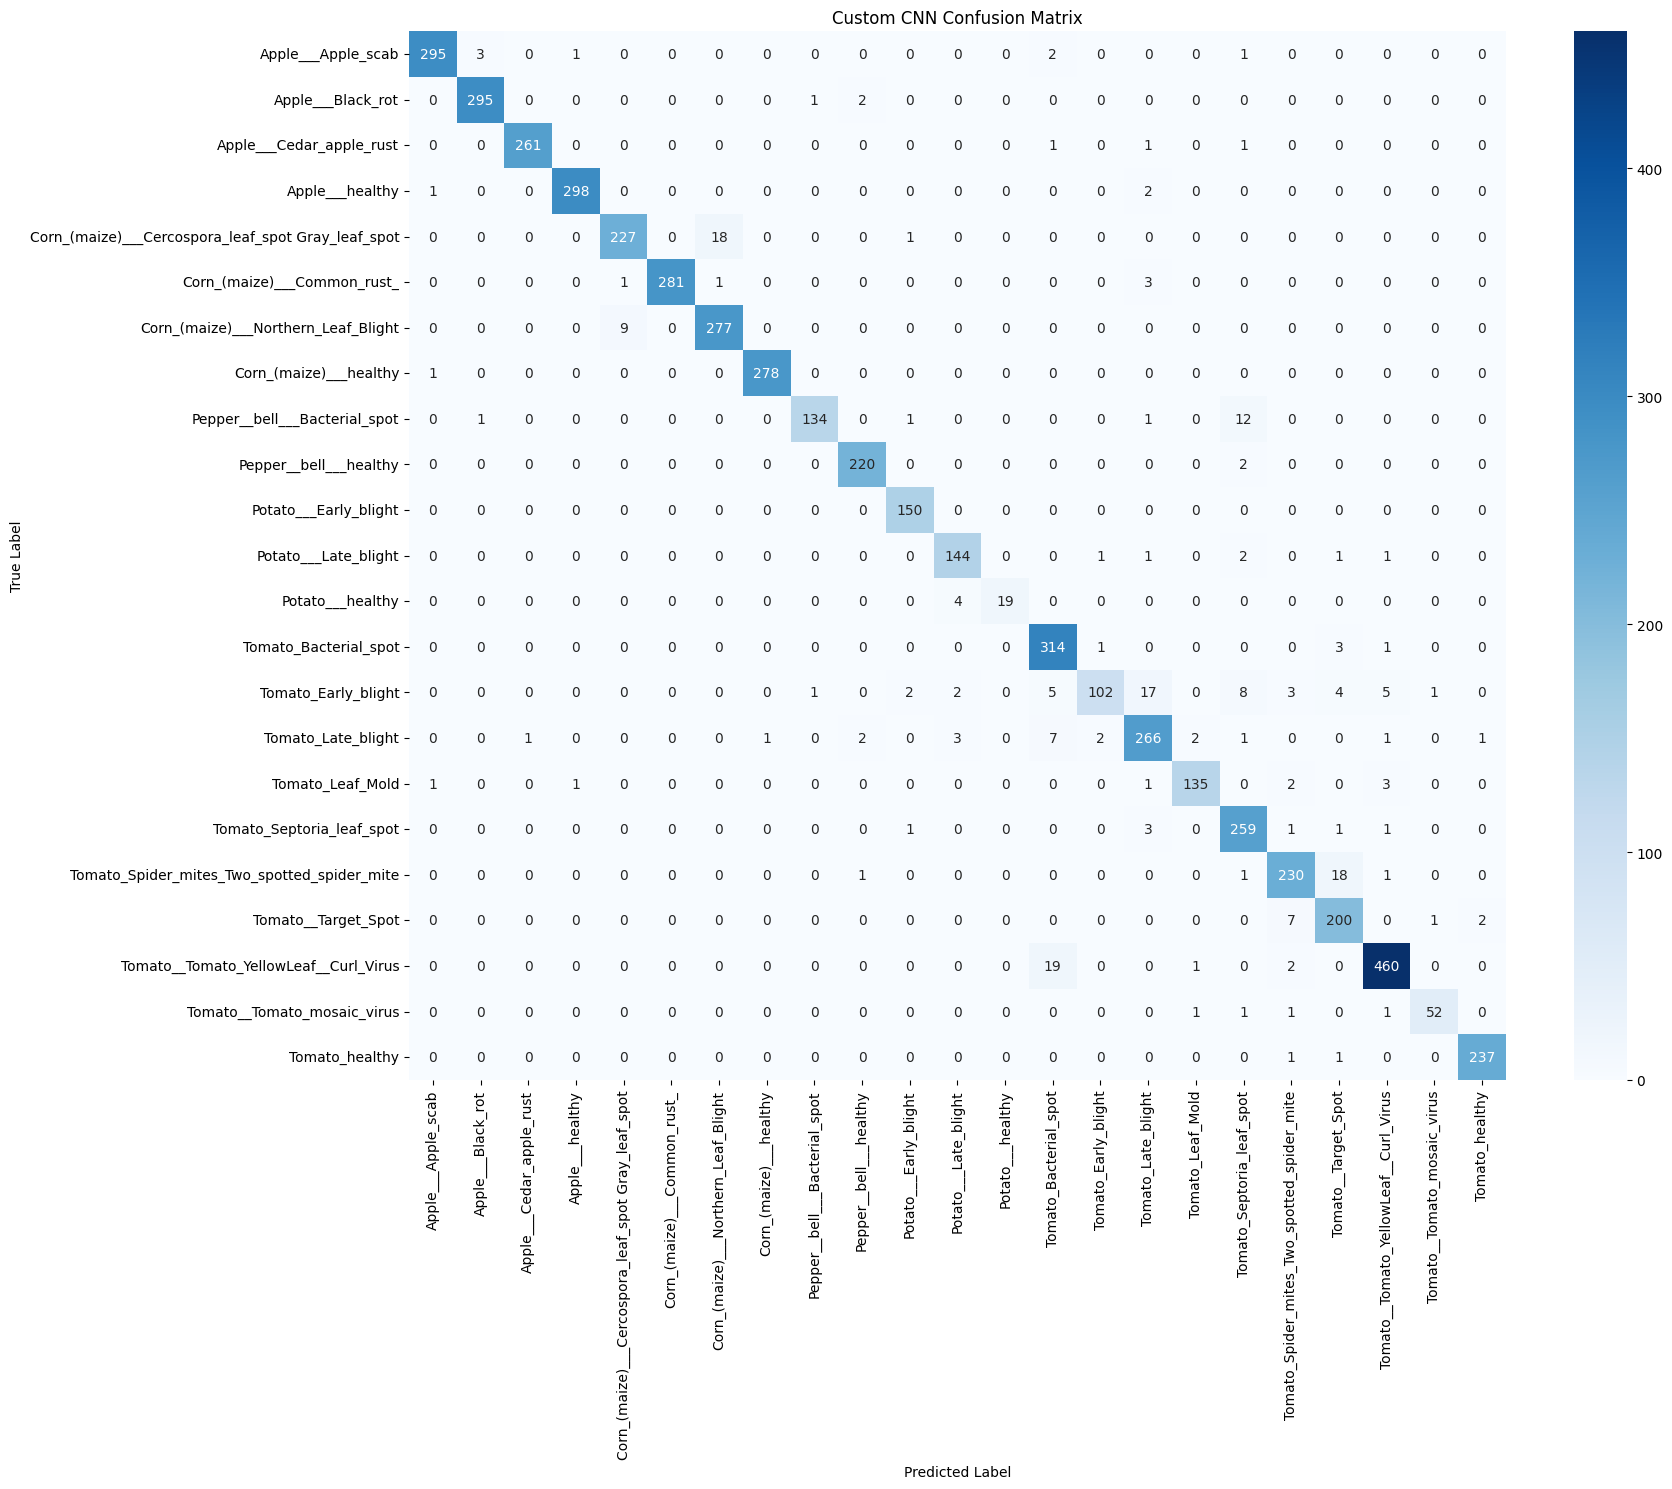

STEP 15 COMPLETED SUCCESSFULLY!


In [71]:
# ==========================================
# STEP 15: CUSTOM CNN TEST EVALUATION
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load Best Model
best_cnn = tf.keras.models.load_model(
    f"{MODEL_DIR}/custom_cnn_best.keras"
)

# Predictions
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

y_prob = best_cnn.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

# Evaluation Metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='weighted')
recall = recall_score(y_true, y_pred, average='weighted')
f1 = f1_score(y_true, y_pred, average='weighted')

print("========== CUSTOM CNN TEST RESULTS ==========")
print("Test Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-Score:", round(f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_true, y_pred,
    target_names=class_names,
    zero_division=0
))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(18, 15))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Custom CNN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print("STEP 15 COMPLETED SUCCESSFULLY!")

In [72]:
# ==========================================
# STEP 16: MOBILENETV2 ARCHITECTURE
# ==========================================

import tensorflow as tf

# Save Custom CNN Results
results = [{
    "Model": "Custom CNN",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1
}]

# Load Pretrained MobileNetV2
mobilenet_base = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

mobilenet_base.trainable = False

# Build Model
inputs = tf.keras.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)
x = tf.keras.layers.Rescaling(1./127.5, offset=-1)(x)

x = mobilenet_base(x, training=False)

x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)

outputs = tf.keras.layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

mobilenet_model = tf.keras.Model(inputs, outputs)

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mobilenet_model.summary()

print("STEP 16 COMPLETED SUCCESSFULLY!")

Model: "functional_77"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_13 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_4 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_5 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 23)             │        29,463 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,287,447 (8.73 MB)

 Trainable params: 29,463 (115.09 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

STEP 16 COMPLETED SUCCESSFULLY!


In [73]:
# ==========================================
# STEP 17: MOBILENETV2 CALLBACKS
# ==========================================

mobilenet_callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=f"{MODEL_DIR}/mobilenetv2_best.keras",
        monitor="val_loss",
        save_best_only=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7
    ),

    tf.keras.callbacks.CSVLogger(
        f"{MODEL_DIR}/mobilenetv2_training.csv"
    )
]

print("MobileNetV2 Callbacks:", len(mobilenet_callbacks))
print("Early Stopping: Ready")
print("Model Checkpoint: Ready")
print("Learning Rate Scheduler: Ready")
print("CSV Logger: Ready")

print("\nSTEP 17 COMPLETED SUCCESSFULLY!")

MobileNetV2 Callbacks: 4
Early Stopping: Ready
Model Checkpoint: Ready
Learning Rate Scheduler: Ready
CSV Logger: Ready

STEP 17 COMPLETED SUCCESSFULLY!


In [74]:
# ==========================================
# STEP 18: MOBILENETV2 TRAINING
# ==========================================

history_mobilenet = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=mobilenet_callbacks,
    verbose=1
)

print("\nMOBILENETV2 TRAINING COMPLETED!")

Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 60s 71ms/step - accuracy: 0.4466 - loss: 1.8996 - val_accuracy: 0.7561 - val_loss: 1.0231 - learning_rate: 1.0000e-04
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 54s 69ms/step - accuracy: 0.7238 - loss: 0.9544 - val_accuracy: 0.8293 - val_loss: 0.6919 - learning_rate: 1.0000e-04
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 54s 69ms/step - accuracy: 0.7913 - loss: 0.7097 - val_accuracy: 0.8545 - val_loss: 0.5599 - learning_rate: 1.0000e-04
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 54s 69ms/step - accuracy: 0.8203 - loss: 0.6028 - val_accuracy: 0.8724 - val_loss: 0.4792 - learning_rate: 1.0000e-04
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 54s 70ms/step - accuracy: 0.8361 - loss: 0.5354 - val_accuracy: 0.8778 - val_loss: 0.4388 - learning_rate: 1.0000e-04
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 54s 69ms/step - accuracy: 0.8566 - loss: 0.4778 - val_accuracy: 0.8895 - val_loss: 0.3989 - learning_rate: 1.0000e-04
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 54s 69ms/ste

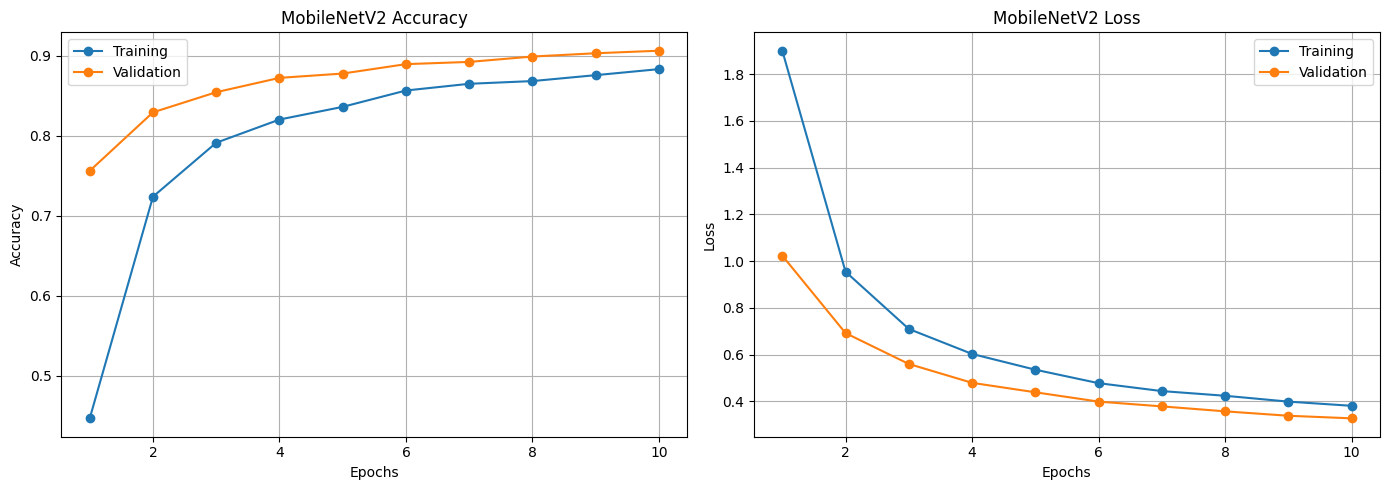

STEP 19 COMPLETED SUCCESSFULLY!


In [76]:
# ==========================================
# STEP 19: MOBILENETV2 TRAINING GRAPHS
# ==========================================

import matplotlib.pyplot as plt

history = history_mobilenet.history
epochs_range = range(1, len(history['accuracy']) + 1)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, history['accuracy'], marker='o', label='Training')
plt.plot(epochs_range, history['val_accuracy'], marker='o', label='Validation')
plt.title('MobileNetV2 Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history['loss'], marker='o', label='Training')
plt.plot(epochs_range, history['val_loss'], marker='o', label='Validation')
plt.title('MobileNetV2 Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig(f"{MODEL_DIR}/mobilenetv2_training_graphs.png", dpi=300)
plt.show()

print("STEP 19 COMPLETED SUCCESSFULLY!")

168/168 ━━━━━━━━━━━━━━━━━━━━ 11s 56ms/step
========== MOBILENETV2 TEST RESULTS ==========
Test Accuracy: 89.74 %
Precision: 0.901
Recall: 0.8974
F1-Score: 0.8942

Classification Report:
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.98      0.95      0.96       302
                                 Apple___Black_rot       0.98      0.98      0.98       298
                          Apple___Cedar_apple_rust       0.98      0.97      0.98       264
                                   Apple___healthy       0.96      0.98      0.97       301
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.97      0.77      0.86       246
                       Corn_(maize)___Common_rust_       0.97      0.99      0.98       286
               Corn_(maize)___Northern_Leaf_Blight       0.84      0.97      0.90       286
                            Corn_(maize)___healthy       1.00      0.99      

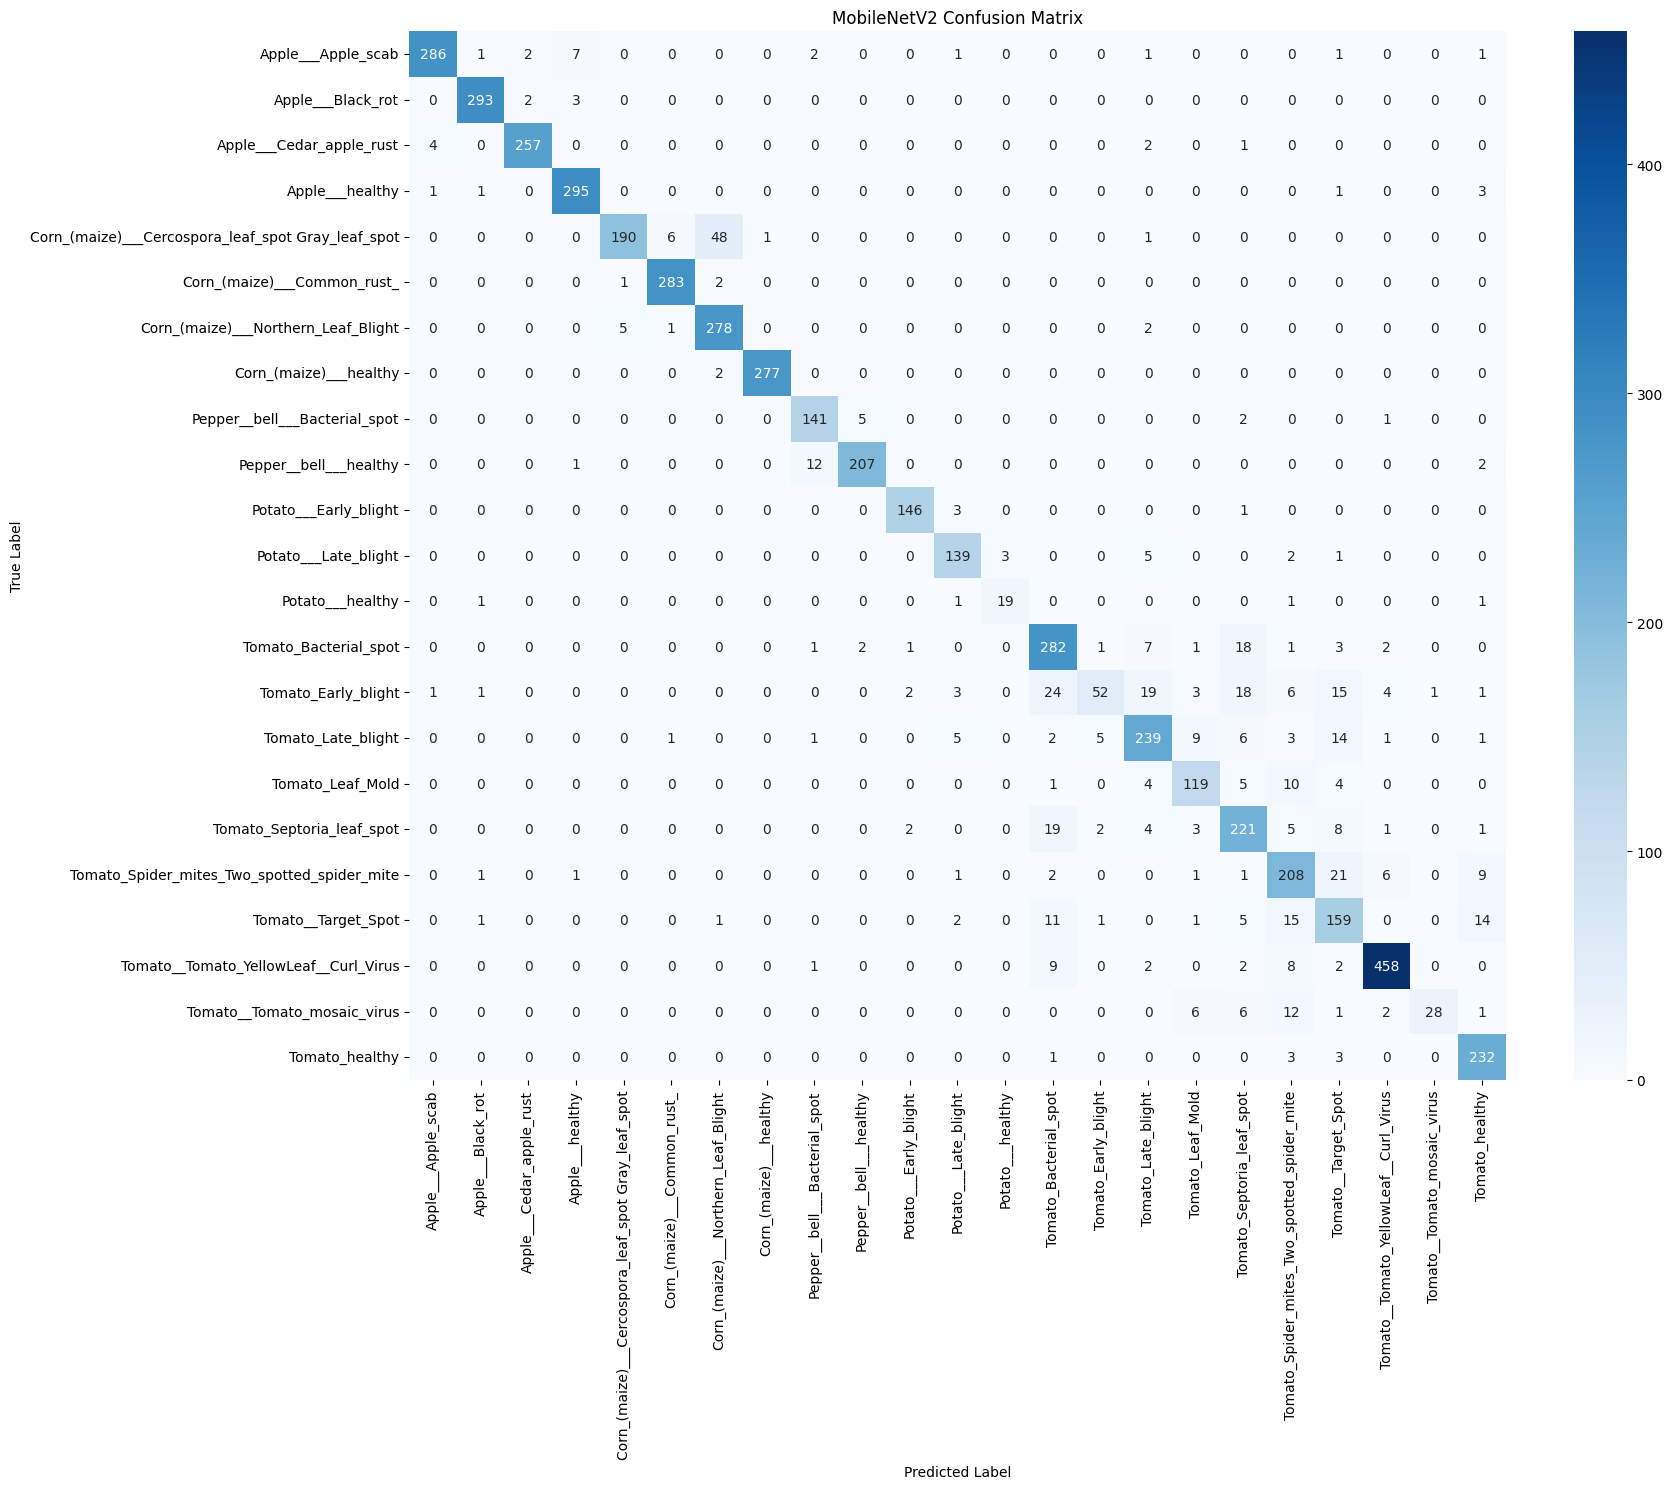


STEP 20 COMPLETED SUCCESSFULLY!


In [77]:
# ==========================================
# STEP 20: MOBILENETV2 TEST EVALUATION
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    classification_report, confusion_matrix
)

best_mobilenet = tf.keras.models.load_model(
    f"{MODEL_DIR}/mobilenetv2_best.keras"
)

y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

y_prob = best_mobilenet.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average="weighted", zero_division=0)
recall = recall_score(y_true, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)

print("========== MOBILENETV2 TEST RESULTS ==========")
print("Test Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-Score:", round(f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_true, y_pred,
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(18, 15))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("MobileNetV2 Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Save Results
results.append({
    "Model": "MobileNetV2",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1
})

print("\nSTEP 20 COMPLETED SUCCESSFULLY!")

In [78]:
# ==========================================
# STEP 21: RESNET50 ARCHITECTURE
# ==========================================

import tensorflow as tf

resnet_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.15),
    tf.keras.layers.RandomZoom(0.15)
])

resnet_base = tf.keras.applications.ResNet50(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

resnet_base.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))

x = resnet_augmentation(inputs)
x = tf.keras.applications.resnet50.preprocess_input(x)

x = resnet_base(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)

outputs = tf.keras.layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

resnet_model = tf.keras.Model(inputs, outputs)

# Build augmentation variables before training
resnet_augmentation(
    tf.zeros((1, 224, 224, 3)),
    training=True
)

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

resnet_model.summary()

print("STEP 21 COMPLETED SUCCESSFULLY!")

Model: "functional_83"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_15      │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_6        │ (None, 224, 224,  │          0 │ input_layer_15[0… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_3          │ (None, 224, 224)  │          0 │ sequential_6[0][… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_4          │ (None, 224, 224)  │          0 │ sequential_6[0][… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_5          │ (None, 224, 224)  │          0 │ sequential_6[0][… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack_1 (Stack)     │ (None, 224, 224,  │          0 │ get_item_3[0][0], │
│                     │ 3)                │            │ get_item_4[0][0], │
│                     │                   │            │ get_item_5[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 224, 224,  │          0 │ stack_1[0][0]     │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet50            │ (None, 7, 7,      │ 23,587,712 │ add_1[0][0]       │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet50[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 2048)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 23)        │     47,127 │ dropout_6[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 23,634,839 (90.16 MB)

 Trainable params: 47,127 (184.09 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

STEP 21 COMPLETED SUCCESSFULLY!


In [79]:
# ==========================================
# STEP 22: RESNET50 CALLBACKS
# ==========================================

resnet_callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=f"{MODEL_DIR}/resnet50_best.keras",
        monitor="val_loss",
        save_best_only=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7
    ),

    tf.keras.callbacks.CSVLogger(
        f"{MODEL_DIR}/resnet50_training.csv"
    )
]

print("Total Callbacks:", len(resnet_callbacks))
print("Early Stopping: Ready")
print("Model Checkpoint: Ready")
print("Learning Rate Scheduler: Ready")
print("CSV Logger: Ready")

print("\nSTEP 22 COMPLETED SUCCESSFULLY!")

Total Callbacks: 4
Early Stopping: Ready
Model Checkpoint: Ready
Learning Rate Scheduler: Ready
CSV Logger: Ready

STEP 22 COMPLETED SUCCESSFULLY!


In [80]:
# ==========================================
# STEP 23: RESNET50 TRAINING
# ==========================================

history_resnet = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=resnet_callbacks,
    verbose=1
)

print("\nRESNET50 TRAINING COMPLETED!")

Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 144s 176ms/step - accuracy: 0.5428 - loss: 1.6106 - val_accuracy: 0.8155 - val_loss: 0.7540 - learning_rate: 1.0000e-04
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 135s 173ms/step - accuracy: 0.8085 - loss: 0.7020 - val_accuracy: 0.8666 - val_loss: 0.4945 - learning_rate: 1.0000e-04
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 135s 173ms/step - accuracy: 0.8621 - loss: 0.5011 - val_accuracy: 0.8890 - val_loss: 0.3884 - learning_rate: 1.0000e-04
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 135s 173ms/step - accuracy: 0.8908 - loss: 0.4001 - val_accuracy: 0.8905 - val_loss: 0.3514 - learning_rate: 1.0000e-04
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 135s 173ms/step - accuracy: 0.9023 - loss: 0.3477 - val_accuracy: 0.9086 - val_loss: 0.3030 - learning_rate: 1.0000e-04
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 135s 173ms/step - accuracy: 0.9148 - loss: 0.3042 - val_accuracy: 0.9177 - val_loss: 0.2695 - learning_rate: 1.0000e-04
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 

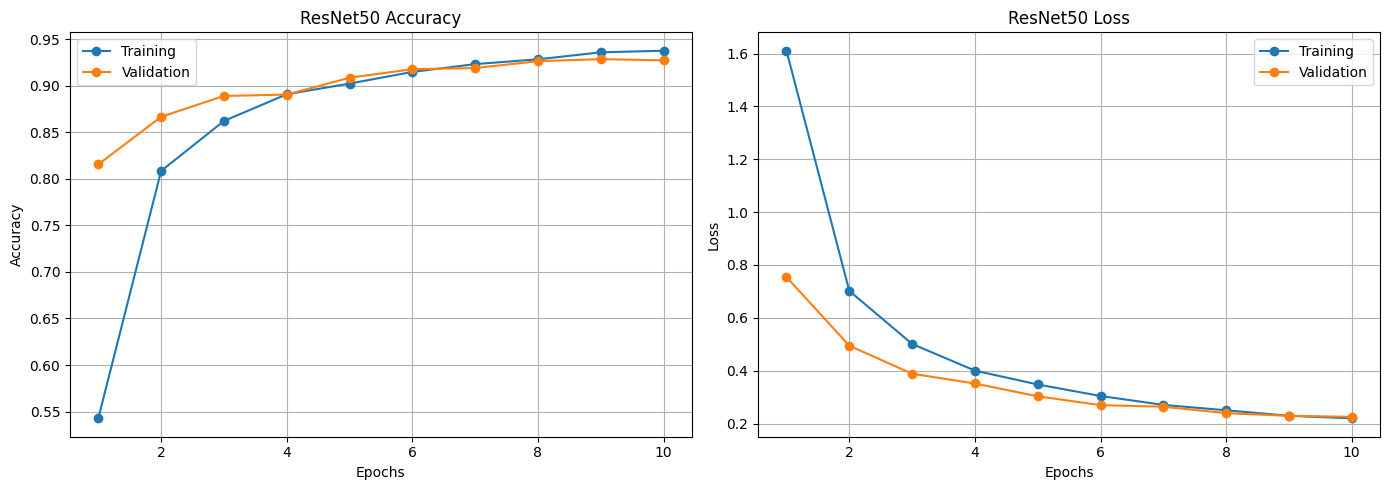

STEP 24 COMPLETED SUCCESSFULLY!


In [81]:
# ==========================================
# STEP 24: RESNET50 TRAINING GRAPHS
# ==========================================

import matplotlib.pyplot as plt

history = history_resnet.history
epochs_range = range(1, len(history['accuracy']) + 1)

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, history['accuracy'], marker='o', label='Training')
plt.plot(epochs_range, history['val_accuracy'], marker='o', label='Validation')
plt.title('ResNet50 Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history['loss'], marker='o', label='Training')
plt.plot(epochs_range, history['val_loss'], marker='o', label='Validation')
plt.title('ResNet50 Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig(f"{MODEL_DIR}/resnet50_training_graphs.png", dpi=300)
plt.show()

print("STEP 24 COMPLETED SUCCESSFULLY!")

168/168 ━━━━━━━━━━━━━━━━━━━━ 26s 147ms/step
========== RESNET50 TEST RESULTS ==========
Test Accuracy: 92.57 %
Precision: 0.9326
Recall: 0.9257
F1-Score: 0.9253

Classification Report:
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.97      0.98      0.98       302
                                 Apple___Black_rot       1.00      0.98      0.99       298
                          Apple___Cedar_apple_rust       1.00      0.98      0.99       264
                                   Apple___healthy       0.97      0.98      0.98       301
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.95      0.95      0.95       246
                       Corn_(maize)___Common_rust_       1.00      1.00      1.00       286
               Corn_(maize)___Northern_Leaf_Blight       0.95      0.96      0.96       286
                            Corn_(maize)___healthy       1.00      1.00      1

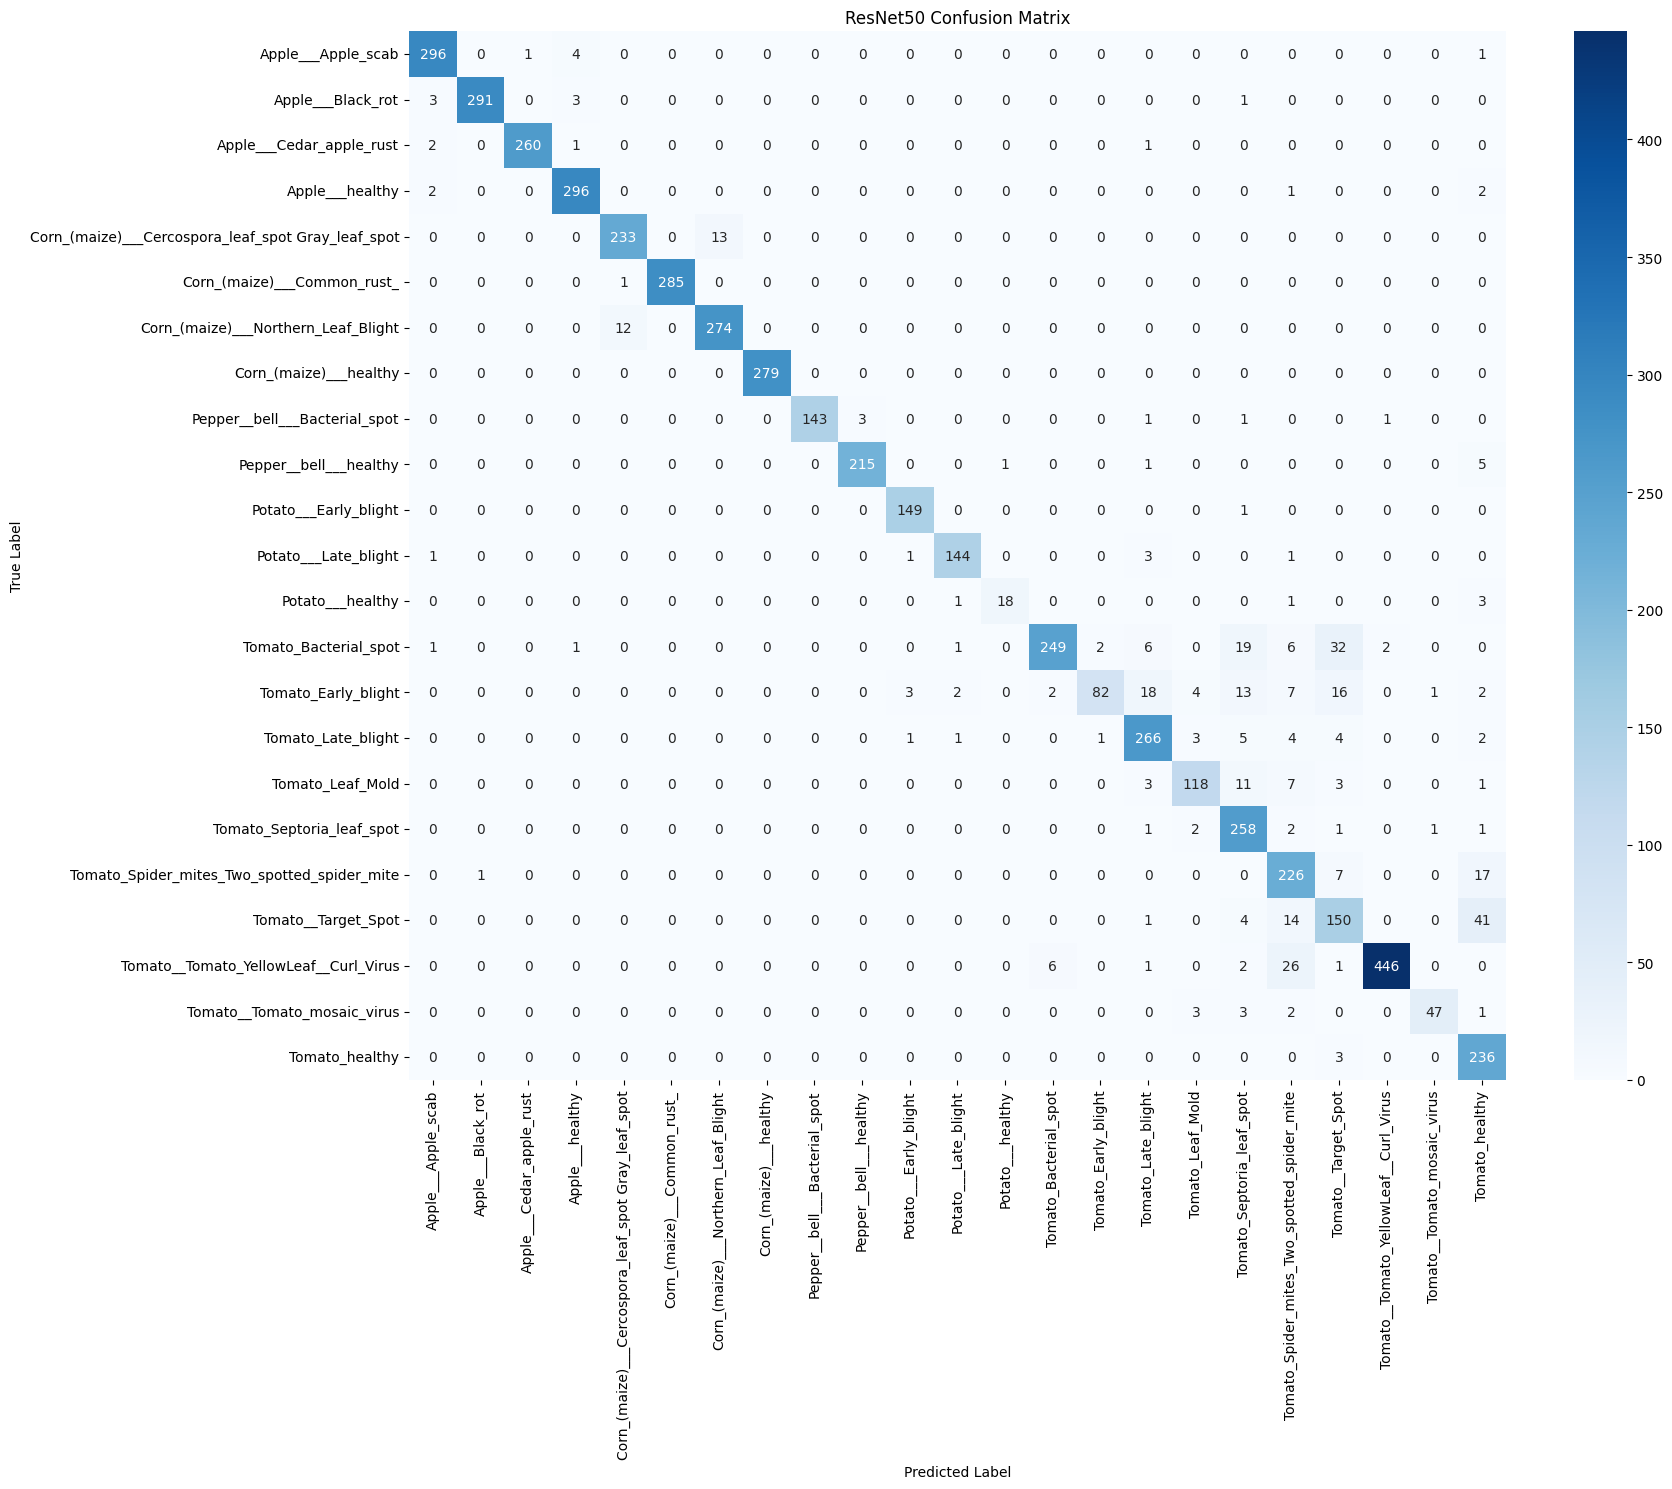


STEP 25 COMPLETED SUCCESSFULLY!


In [82]:
# ==========================================
# STEP 25: RESNET50 TEST EVALUATION
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    classification_report, confusion_matrix
)

best_resnet = tf.keras.models.load_model(
    f"{MODEL_DIR}/resnet50_best.keras"
)

y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

y_prob = best_resnet.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average="weighted", zero_division=0)
recall = recall_score(y_true, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)

print("========== RESNET50 TEST RESULTS ==========")
print("Test Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-Score:", round(f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_true, y_pred,
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(18, 15))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("ResNet50 Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

results.append({
    "Model": "ResNet50",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1
})

print("\nSTEP 25 COMPLETED SUCCESSFULLY!")

In [83]:
# ==========================================
# STEP 26: EFFICIENTNETB0 MODEL ARCHITECTURE
# ==========================================

import tensorflow as tf
from tensorflow.keras.layers import (
    Input, GlobalAveragePooling2D,
    Dense, Dropout, RandomFlip,
    RandomRotation, RandomZoom
)
from tensorflow.keras.models import Model

# Data Augmentation
efficientnet_augmentation = tf.keras.Sequential([
    RandomFlip("horizontal"),
    RandomRotation(0.15),
    RandomZoom(0.15)
])

# Pretrained EfficientNetB0
efficientnet_base = tf.keras.applications.EfficientNetB0(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

efficientnet_base.trainable = False

# Model Architecture
inputs = Input(shape=(224, 224, 3))

x = efficientnet_augmentation(inputs)

x = efficientnet_base(x, training=False)

x = GlobalAveragePooling2D()(x)

x = Dropout(0.3)(x)

outputs = Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

efficientnet_model = Model(
    inputs=inputs,
    outputs=outputs
)

# Build Augmentation Variables
efficientnet_augmentation(
    tf.zeros((1, 224, 224, 3)),
    training=True
)

# Compile Model
efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Model Summary
efficientnet_model.summary()

print("\nSTEP 26 COMPLETED SUCCESSFULLY!")

Model: "functional_88"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_18 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_7 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_7      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 23)             │        29,463 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,079,034 (15.56 MB)

 Trainable params: 29,463 (115.09 KB)

 Non-trainable params: 4,049,571 (15.45 MB)


STEP 26 COMPLETED SUCCESSFULLY!


In [84]:
# ==========================================
# STEP 27: EFFICIENTNETB0 CALLBACKS
# ==========================================

efficientnet_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=f"{MODEL_DIR}/efficientnetb0_best.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        f"{MODEL_DIR}/efficientnetb0_training.csv"
    )
]

print("EfficientNetB0 Callbacks Created Successfully!")
print("\nSTEP 27 COMPLETED SUCCESSFULLY!")

EfficientNetB0 Callbacks Created Successfully!

STEP 27 COMPLETED SUCCESSFULLY!


In [85]:
# ==========================================
# STEP 28: EFFICIENTNETB0 MODEL TRAINING
# ==========================================

history_efficientnet = efficientnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=efficientnet_callbacks,
    verbose=1
)

print("\nSTEP 28 COMPLETED SUCCESSFULLY!")

Epoch 1/10


E0000 00:00:1794337314.247034      49 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_88_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


781/782 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.3081 - loss: 2.5172
Epoch 1: val_loss improved from None to 1.40904, saving model to /kaggle/working/Trained_Models/efficientnetb0_best.keras

Epoch 1: finished saving model to /kaggle/working/Trained_Models/efficientnetb0_best.keras
782/782 ━━━━━━━━━━━━━━━━━━━━ 85s 96ms/step - accuracy: 0.4674 - loss: 2.0634 - val_accuracy: 0.7195 - val_loss: 1.4090 - learning_rate: 1.0000e-04
Epoch 2/10
781/782 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.7021 - loss: 1.3005
Epoch 2: val_loss improved from 1.40904 to 0.97337, saving model to /kaggle/working/Trained_Models/efficientnetb0_best.keras

Epoch 2: finished saving model to /kaggle/working/Trained_Models/efficientnetb0_best.keras
782/782 ━━━━━━━━━━━━━━━━━━━━ 72s 92ms/step - accuracy: 0.7345 - loss: 1.1796 - val_accuracy: 0.7867 - val_loss: 0.9734 - learning_rate: 1.0000e-04
Epoch 3/10
781/782 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.7833 - loss: 0.9375
Epoch 3: val_loss improve

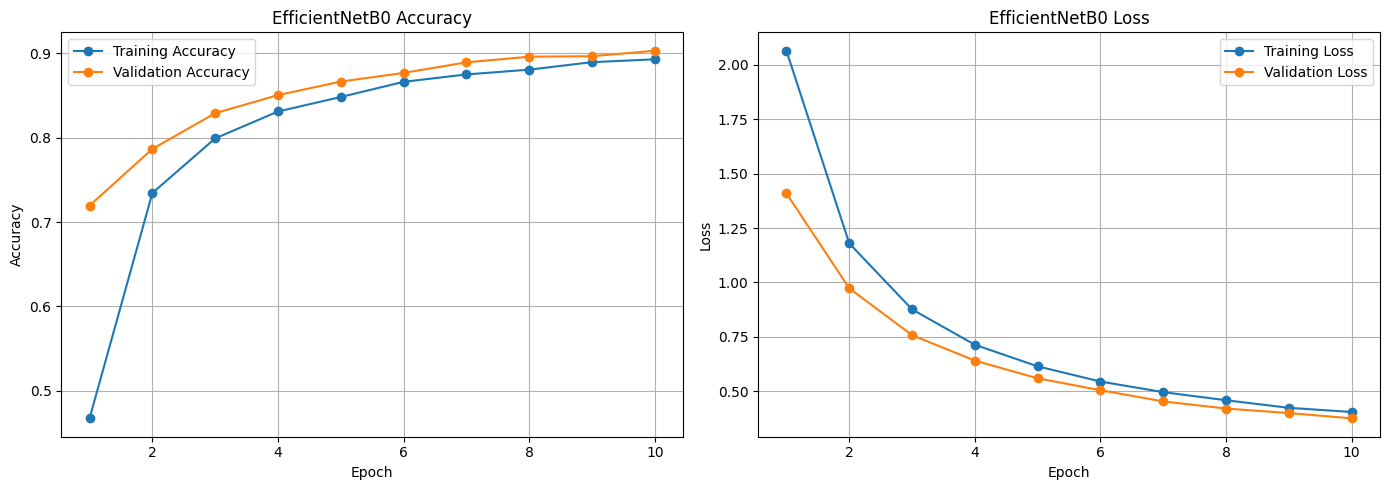

STEP 29 COMPLETED SUCCESSFULLY!


In [86]:
# ==========================================
# STEP 29: EFFICIENTNETB0 TRAINING GRAPHS
# ==========================================

import matplotlib.pyplot as plt

history = history_efficientnet.history
epochs_range = range(1, len(history["accuracy"]) + 1)

plt.figure(figsize=(14, 5))

# Accuracy Graph
plt.subplot(1, 2, 1)

plt.plot(epochs_range, history["accuracy"],
         marker="o", label="Training Accuracy")

plt.plot(epochs_range, history["val_accuracy"],
         marker="o", label="Validation Accuracy")

plt.title("EfficientNetB0 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss Graph
plt.subplot(1, 2, 2)

plt.plot(epochs_range, history["loss"],
         marker="o", label="Training Loss")

plt.plot(epochs_range, history["val_loss"],
         marker="o", label="Validation Loss")

plt.title("EfficientNetB0 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    f"{MODEL_DIR}/efficientnetb0_training_graphs.png",
    dpi=300
)

plt.show()

print("STEP 29 COMPLETED SUCCESSFULLY!")

In [87]:
# ==========================================
# STEP 30: VERIFY SAVED MODEL AND GRAPH
# ==========================================

import os

checkpoint_path = f"{MODEL_DIR}/efficientnetb0_best.keras"
graph_path = f"{MODEL_DIR}/efficientnetb0_training_graphs.png"

print("EfficientNetB0 Checkpoint Exists:",
      os.path.exists(checkpoint_path))

print("Training Graph Exists:",
      os.path.exists(graph_path))

print("\nSaved Files:")
for file in os.listdir(MODEL_DIR):
    print(file)

print("\nSTEP 30 COMPLETED SUCCESSFULLY!")

EfficientNetB0 Checkpoint Exists: True
Training Graph Exists: True

Saved Files:
mobilenetv2_training_graphs.png
resnet50_training_graphs.png
resnet50_training.csv
efficientnetb0_training.csv
custom_cnn_test_results.csv
custom_cnn_confusion_matrix.png
efficientnetb0_best.keras
efficientnetb0_confusion_matrix.png
final_model_comparison.csv
mobilenetv2_confusion_matrix.png
resnet50_test_results.csv
resnet50_confusion_matrix.png
custom_cnn_training.csv
custom_cnn_best.keras
resnet50_best.keras
efficientnetb0_training_graphs.png
custom_cnn_training_graphs.png
mobilenetv2_best.keras
efficientnetb0_test_results.csv
mobilenetv2_test_results.csv
final_accuracy_comparison.png
mobilenetv2_training.csv

STEP 30 COMPLETED SUCCESSFULLY!


EfficientNetB0 Model Loaded Successfully!
168/168 ━━━━━━━━━━━━━━━━━━━━ 16s 82ms/step

========== EFFICIENTNETB0 TEST RESULTS ==========
Test Accuracy  : 89.44%
Test Precision : 90.31%
Test Recall    : 89.44%
Test F1-Score  : 89.26%

========== CLASSIFICATION REPORT ==========
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.95      0.91      0.93       302
                                 Apple___Black_rot       0.98      0.98      0.98       298
                          Apple___Cedar_apple_rust       1.00      0.90      0.94       264
                                   Apple___healthy       0.90      0.98      0.94       301
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.94      0.85      0.89       246
                       Corn_(maize)___Common_rust_       1.00      0.99      0.99       286
               Corn_(maize)___Northern_Leaf_Blight       0.87      0.97      0

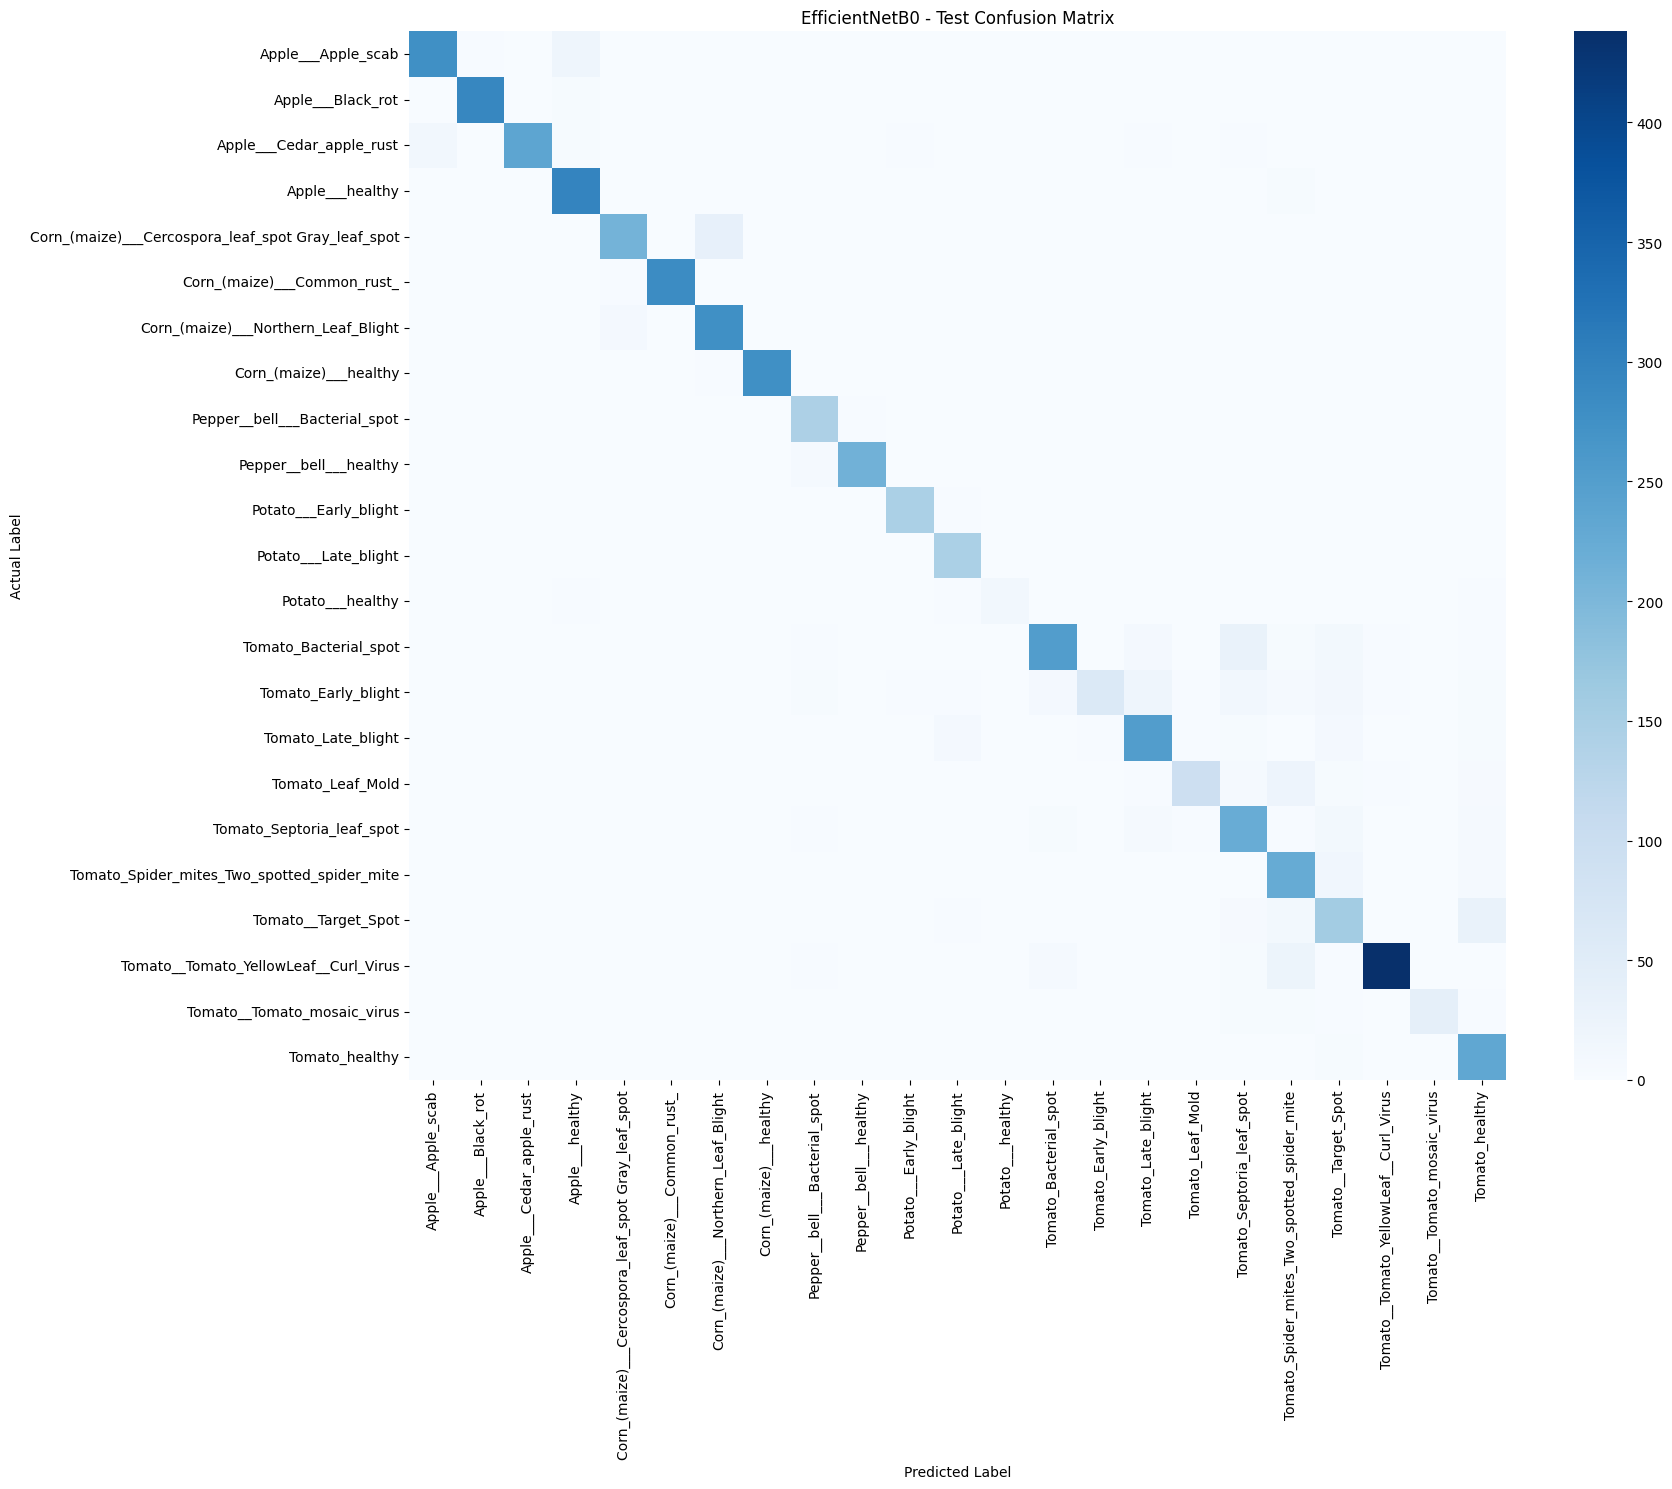


STEP 31 COMPLETED SUCCESSFULLY!


In [88]:

# ==========================================
# STEP 31: EFFICIENTNETB0 TEST EVALUATION
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import tensorflow as tf

# Load Best Model
checkpoint_path = f"{MODEL_DIR}/efficientnetb0_best.keras"

best_efficientnet = tf.keras.models.load_model(
    checkpoint_path,
    compile=False
)

print("EfficientNetB0 Model Loaded Successfully!")

# Actual Test Labels
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Model Predictions
y_prob = best_efficientnet.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# Evaluation Metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(
    y_true, y_pred, average="weighted", zero_division=0
)
recall = recall_score(
    y_true, y_pred, average="weighted", zero_division=0
)
f1 = f1_score(
    y_true, y_pred, average="weighted", zero_division=0
)

print("\n========== EFFICIENTNETB0 TEST RESULTS ==========")
print(f"Test Accuracy  : {accuracy * 100:.2f}%")
print(f"Test Precision : {precision * 100:.2f}%")
print(f"Test Recall    : {recall * 100:.2f}%")
print(f"Test F1-Score  : {f1 * 100:.2f}%")

# Classification Report
print("\n========== CLASSIFICATION REPORT ==========")

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(18, 15))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("EfficientNetB0 - Test Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    f"{MODEL_DIR}/efficientnetb0_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSTEP 31 COMPLETED SUCCESSFULLY!")


In [89]:

# ==========================================
# STEP 32: SAVE EFFICIENTNETB0 TEST RESULTS
# ==========================================

import pandas as pd
import os

efficientnet_results = pd.DataFrame([{
    "Model": "EfficientNetB0",
    "Test Accuracy": accuracy,
    "Test Precision": precision,
    "Test Recall": recall,
    "Test F1-Score": f1
}])

results_path = f"{MODEL_DIR}/efficientnetb0_test_results.csv"

efficientnet_results.to_csv(results_path, index=False)

print("EfficientNetB0 Test Results Saved Successfully!")
print("\nSaved Results:")
print(efficientnet_results)

print("\nFile Exists:", os.path.exists(results_path))

print("\nSTEP 32 COMPLETED SUCCESSFULLY!")


EfficientNetB0 Test Results Saved Successfully!

Saved Results:
            Model  Test Accuracy  Test Precision  Test Recall  Test F1-Score
0  EfficientNetB0       0.894383        0.903099     0.894383        0.89261

File Exists: True

STEP 32 COMPLETED SUCCESSFULLY!


Custom CNN Model Loaded Successfully!
168/168 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step

========== CUSTOM CNN TEST RESULTS ==========
Test Accuracy  : 95.80%
Test Precision : 95.92%
Test Recall    : 95.80%
Test F1-Score  : 95.75%

========== CLASSIFICATION REPORT ==========
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.99      0.98      0.98       302
                                 Apple___Black_rot       0.99      0.99      0.99       298
                          Apple___Cedar_apple_rust       1.00      0.99      0.99       264
                                   Apple___healthy       0.99      0.99      0.99       301
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.96      0.92      0.94       246
                       Corn_(maize)___Common_rust_       1.00      0.98      0.99       286
               Corn_(maize)___Northern_Leaf_Blight       0.94      0.97      0.95      

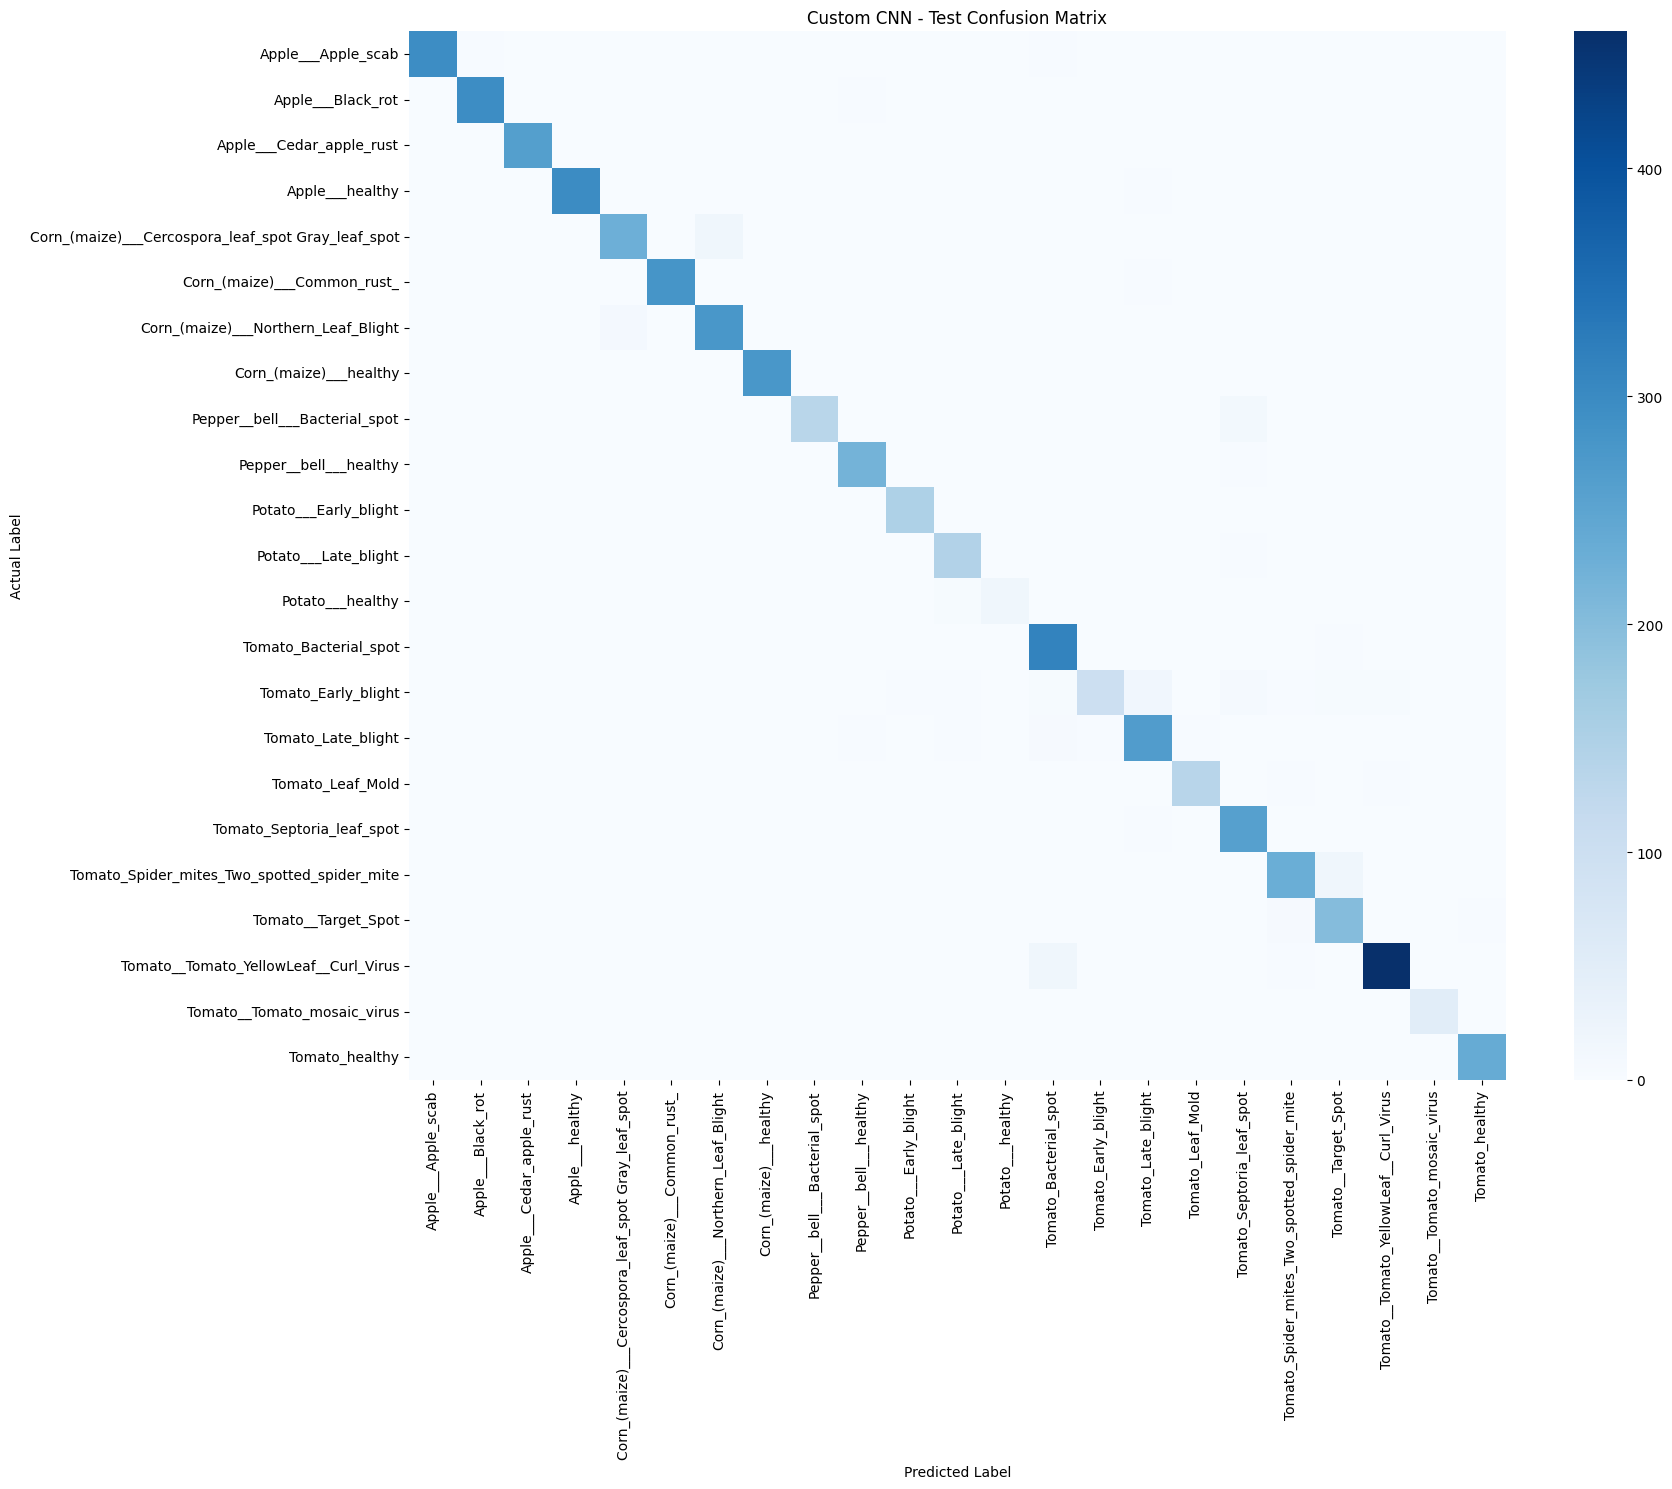


STEP 33 COMPLETED SUCCESSFULLY!


In [90]:

# ==========================================
# STEP 33: CUSTOM CNN TEST EVALUATION
# ==========================================

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load Custom CNN
custom_cnn_path = f"{MODEL_DIR}/custom_cnn_best.keras"

best_custom_cnn = tf.keras.models.load_model(
    custom_cnn_path,
    compile=False
)

print("Custom CNN Model Loaded Successfully!")

# Actual Test Labels
y_true_custom = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Predictions
y_prob_custom = best_custom_cnn.predict(test_ds, verbose=1)
y_pred_custom = np.argmax(y_prob_custom, axis=1)

# Evaluation Metrics
custom_accuracy = accuracy_score(y_true_custom, y_pred_custom)

custom_precision = precision_score(
    y_true_custom, y_pred_custom,
    average="weighted", zero_division=0
)

custom_recall = recall_score(
    y_true_custom, y_pred_custom,
    average="weighted", zero_division=0
)

custom_f1 = f1_score(
    y_true_custom, y_pred_custom,
    average="weighted", zero_division=0
)

print("\n========== CUSTOM CNN TEST RESULTS ==========")
print(f"Test Accuracy  : {custom_accuracy * 100:.2f}%")
print(f"Test Precision : {custom_precision * 100:.2f}%")
print(f"Test Recall    : {custom_recall * 100:.2f}%")
print(f"Test F1-Score  : {custom_f1 * 100:.2f}%")

# Classification Report
print("\n========== CLASSIFICATION REPORT ==========")

print(classification_report(
    y_true_custom,
    y_pred_custom,
    target_names=class_names,
    zero_division=0
))

# Confusion Matrix
cm_custom = confusion_matrix(
    y_true_custom, y_pred_custom
)

plt.figure(figsize=(18, 15))

sns.heatmap(
    cm_custom,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Custom CNN - Test Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    f"{MODEL_DIR}/custom_cnn_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSTEP 33 COMPLETED SUCCESSFULLY!")


In [92]:

# ==========================================
# STEP 34: SAVE CUSTOM CNN TEST RESULTS
# ==========================================

import pandas as pd
import os

custom_results = pd.DataFrame([{
    "Model": "Custom CNN",
    "Test Accuracy": custom_accuracy,
    "Test Precision": custom_precision,
    "Test Recall": custom_recall,
    "Test F1-Score": custom_f1
}])

custom_results_path = f"{MODEL_DIR}/custom_cnn_test_results.csv"

custom_results.to_csv(custom_results_path, index=False)

print("Custom CNN Test Results Saved Successfully!")
print("\nSaved Results:")
print(custom_results)

print("\nFile Exists:", os.path.exists(custom_results_path))

print("\nSTEP 34 COMPLETED SUCCESSFULLY!")


Custom CNN Test Results Saved Successfully!

Saved Results:
        Model  Test Accuracy  Test Precision  Test Recall  Test F1-Score
0  Custom CNN       0.958015        0.959159     0.958015       0.957501

File Exists: True

STEP 34 COMPLETED SUCCESSFULLY!


MobileNetV2 Model Loaded Successfully!
168/168 ━━━━━━━━━━━━━━━━━━━━ 11s 57ms/step

========== MOBILENETV2 TEST RESULTS ==========
Test Accuracy  : 89.74%
Test Precision : 90.10%
Test Recall    : 89.74%
Test F1-Score  : 89.42%

========== CLASSIFICATION REPORT ==========
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.98      0.95      0.96       302
                                 Apple___Black_rot       0.98      0.98      0.98       298
                          Apple___Cedar_apple_rust       0.98      0.97      0.98       264
                                   Apple___healthy       0.96      0.98      0.97       301
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.97      0.77      0.86       246
                       Corn_(maize)___Common_rust_       0.97      0.99      0.98       286
               Corn_(maize)___Northern_Leaf_Blight       0.84      0.97      0.90   

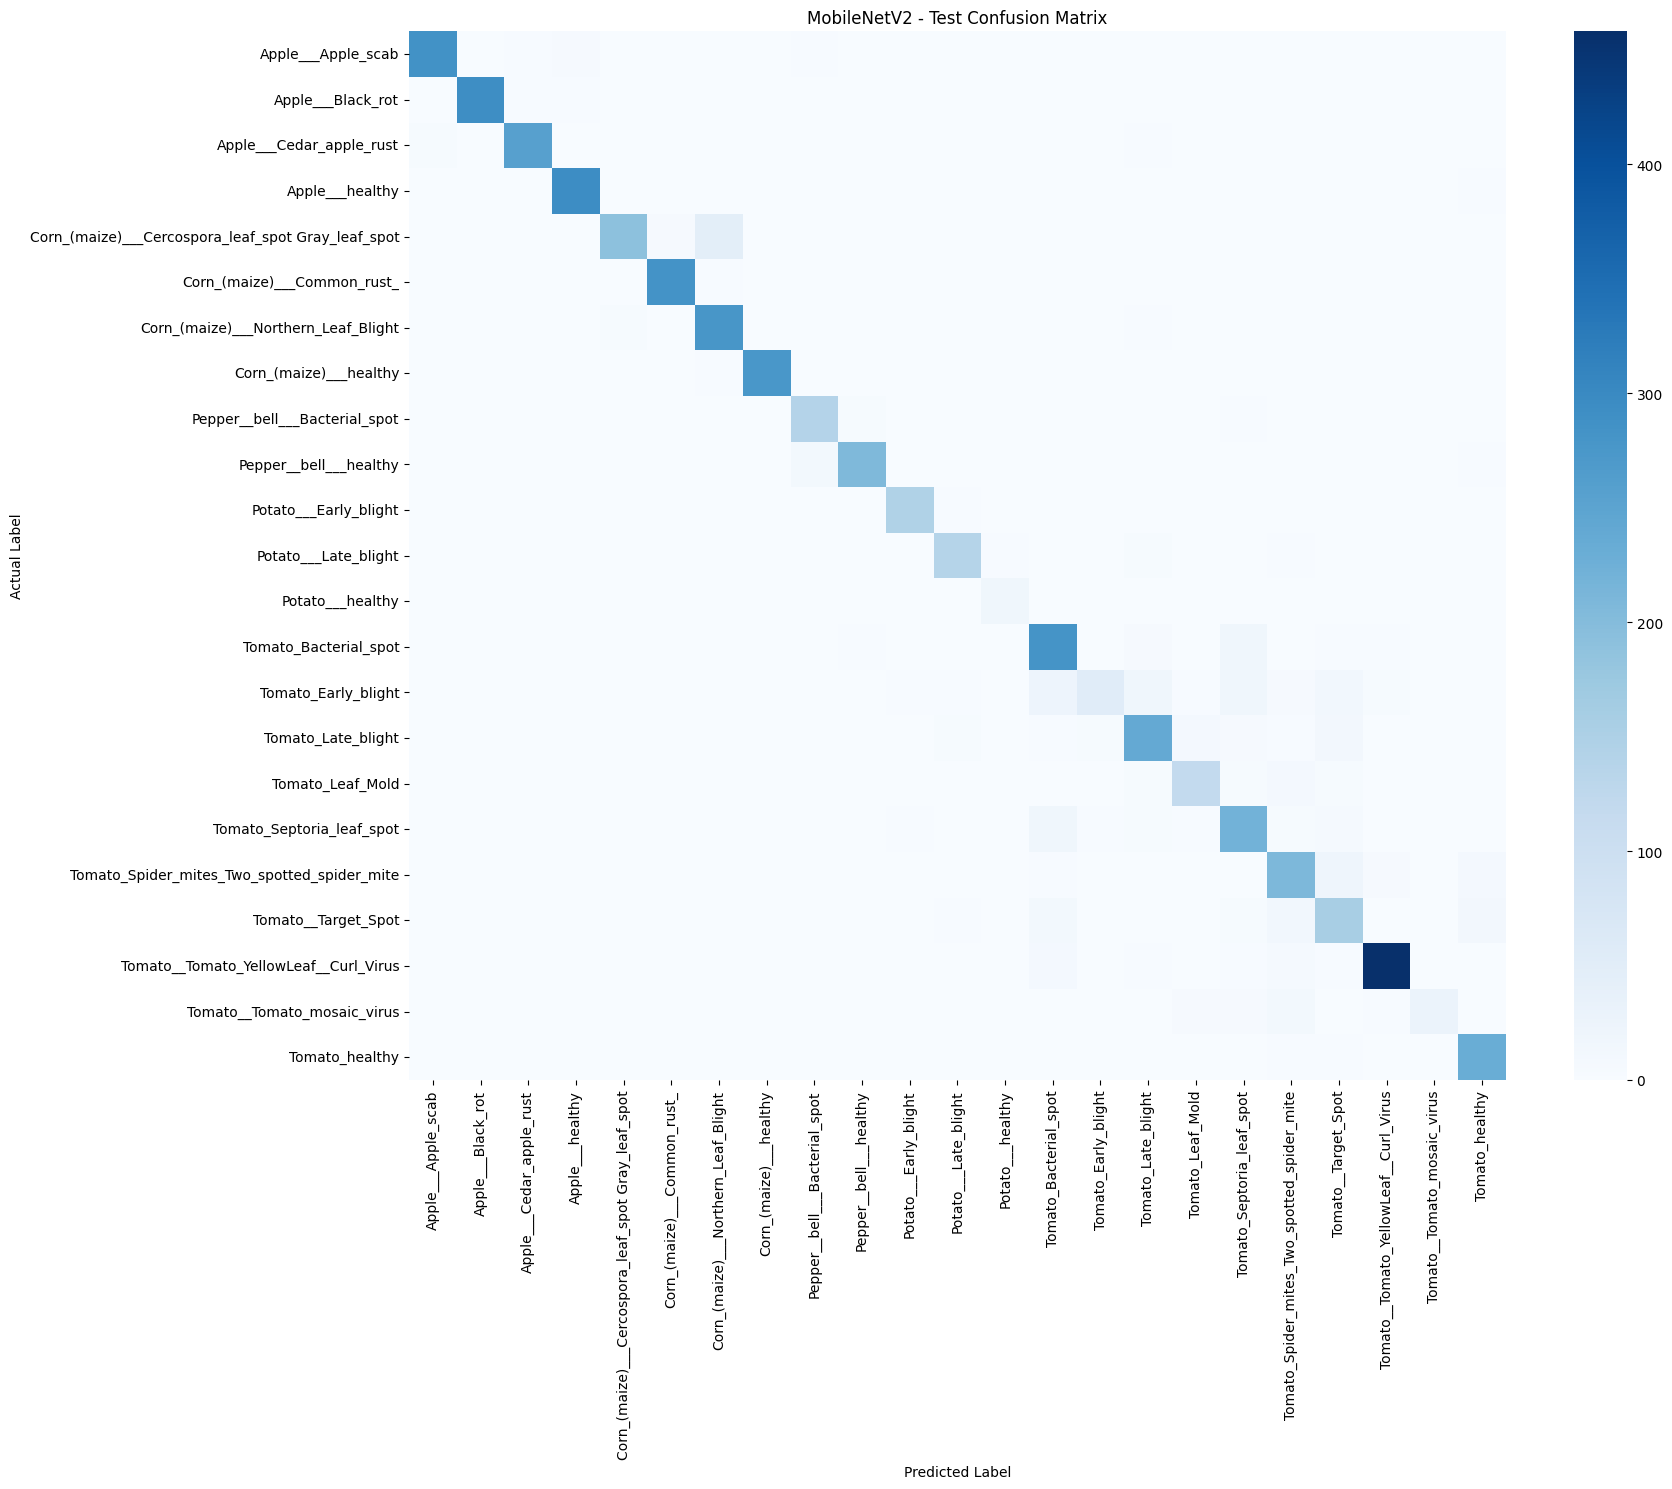


STEP 35 COMPLETED SUCCESSFULLY!


In [93]:

# ==========================================
# STEP 35: MOBILENETV2 TEST EVALUATION
# ==========================================

# Load MobileNetV2
mobilenet_path = f"{MODEL_DIR}/mobilenetv2_best.keras"

best_mobilenet = tf.keras.models.load_model(
    mobilenet_path,
    compile=False
)

print("MobileNetV2 Model Loaded Successfully!")

# Actual Test Labels
y_true_mobile = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Predictions
y_prob_mobile = best_mobilenet.predict(test_ds, verbose=1)
y_pred_mobile = np.argmax(y_prob_mobile, axis=1)

# Evaluation Metrics
mobile_accuracy = accuracy_score(y_true_mobile, y_pred_mobile)

mobile_precision = precision_score(
    y_true_mobile, y_pred_mobile,
    average="weighted", zero_division=0
)

mobile_recall = recall_score(
    y_true_mobile, y_pred_mobile,
    average="weighted", zero_division=0
)

mobile_f1 = f1_score(
    y_true_mobile, y_pred_mobile,
    average="weighted", zero_division=0
)

print("\n========== MOBILENETV2 TEST RESULTS ==========")
print(f"Test Accuracy  : {mobile_accuracy * 100:.2f}%")
print(f"Test Precision : {mobile_precision * 100:.2f}%")
print(f"Test Recall    : {mobile_recall * 100:.2f}%")
print(f"Test F1-Score  : {mobile_f1 * 100:.2f}%")

# Classification Report
print("\n========== CLASSIFICATION REPORT ==========")

print(classification_report(
    y_true_mobile,
    y_pred_mobile,
    target_names=class_names,
    zero_division=0
))

# Confusion Matrix
cm_mobile = confusion_matrix(
    y_true_mobile, y_pred_mobile
)

plt.figure(figsize=(18, 15))

sns.heatmap(
    cm_mobile,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("MobileNetV2 - Test Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    f"{MODEL_DIR}/mobilenetv2_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSTEP 35 COMPLETED SUCCESSFULLY!")


In [94]:

# ==========================================
# STEP 36: SAVE MOBILENETV2 TEST RESULTS
# ==========================================

import pandas as pd
import os

mobile_results = pd.DataFrame([{
    "Model": "MobileNetV2",
    "Test Accuracy": mobile_accuracy,
    "Test Precision": mobile_precision,
    "Test Recall": mobile_recall,
    "Test F1-Score": mobile_f1
}])

mobile_results_path = f"{MODEL_DIR}/mobilenetv2_test_results.csv"

mobile_results.to_csv(mobile_results_path, index=False)

print("MobileNetV2 Test Results Saved Successfully!")
print("\nSaved Results:")
print(mobile_results)

print("\nFile Exists:", os.path.exists(mobile_results_path))

print("\nSTEP 36 COMPLETED SUCCESSFULLY!")


MobileNetV2 Test Results Saved Successfully!

Saved Results:
         Model  Test Accuracy  Test Precision  Test Recall  Test F1-Score
0  MobileNetV2       0.897369        0.901024     0.897369       0.894162

File Exists: True

STEP 36 COMPLETED SUCCESSFULLY!


ResNet50 Model Loaded Successfully!
168/168 ━━━━━━━━━━━━━━━━━━━━ 27s 148ms/step

========== RESNET50 TEST RESULTS ==========
Test Accuracy  : 92.57%
Test Precision : 93.26%
Test Recall    : 92.57%
Test F1-Score  : 92.53%

========== CLASSIFICATION REPORT ==========
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.97      0.98      0.98       302
                                 Apple___Black_rot       1.00      0.98      0.99       298
                          Apple___Cedar_apple_rust       1.00      0.98      0.99       264
                                   Apple___healthy       0.97      0.98      0.98       301
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.95      0.95      0.95       246
                       Corn_(maize)___Common_rust_       1.00      1.00      1.00       286
               Corn_(maize)___Northern_Leaf_Blight       0.95      0.96      0.96       2

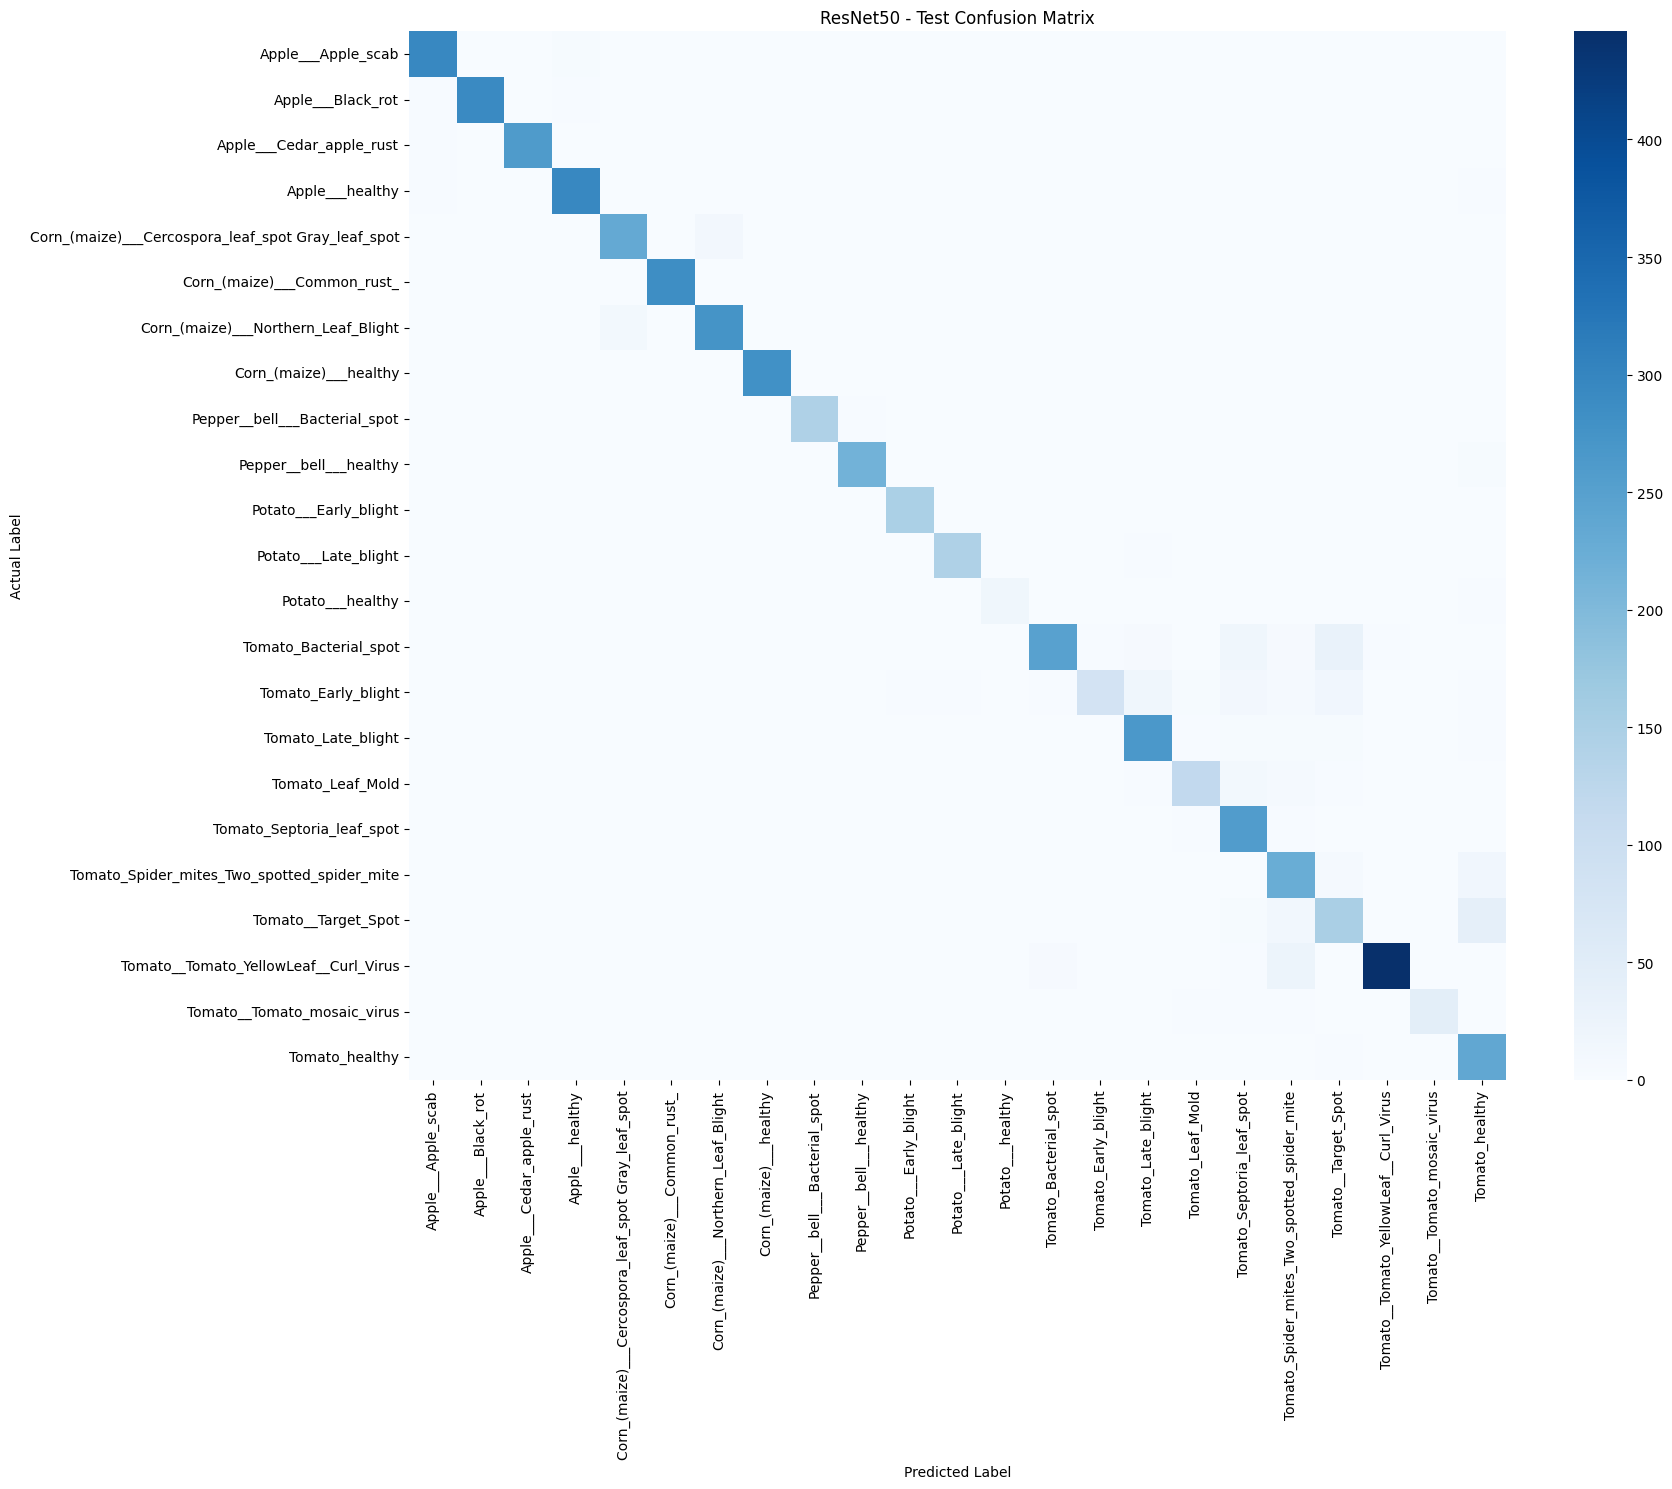


STEP 37 COMPLETED SUCCESSFULLY!


In [95]:

# ==========================================
# STEP 37: RESNET50 TEST EVALUATION
# ==========================================

# Load ResNet50
resnet_path = f"{MODEL_DIR}/resnet50_best.keras"

best_resnet = tf.keras.models.load_model(
    resnet_path,
    compile=False
)

print("ResNet50 Model Loaded Successfully!")

# Actual Test Labels
y_true_resnet = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Predictions
y_prob_resnet = best_resnet.predict(test_ds, verbose=1)
y_pred_resnet = np.argmax(y_prob_resnet, axis=1)

# Evaluation Metrics
resnet_accuracy = accuracy_score(y_true_resnet, y_pred_resnet)

resnet_precision = precision_score(
    y_true_resnet, y_pred_resnet,
    average="weighted", zero_division=0
)

resnet_recall = recall_score(
    y_true_resnet, y_pred_resnet,
    average="weighted", zero_division=0
)

resnet_f1 = f1_score(
    y_true_resnet, y_pred_resnet,
    average="weighted", zero_division=0
)

print("\n========== RESNET50 TEST RESULTS ==========")
print(f"Test Accuracy  : {resnet_accuracy * 100:.2f}%")
print(f"Test Precision : {resnet_precision * 100:.2f}%")
print(f"Test Recall    : {resnet_recall * 100:.2f}%")
print(f"Test F1-Score  : {resnet_f1 * 100:.2f}%")

# Classification Report
print("\n========== CLASSIFICATION REPORT ==========")

print(classification_report(
    y_true_resnet,
    y_pred_resnet,
    target_names=class_names,
    zero_division=0
))

# Confusion Matrix
cm_resnet = confusion_matrix(
    y_true_resnet, y_pred_resnet
)

plt.figure(figsize=(18, 15))

sns.heatmap(
    cm_resnet,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("ResNet50 - Test Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    f"{MODEL_DIR}/resnet50_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSTEP 37 COMPLETED SUCCESSFULLY!")


In [96]:

# ==========================================
# STEP 38: SAVE RESNET50 TEST RESULTS
# ==========================================

import pandas as pd
import os

resnet_results = pd.DataFrame([{
    "Model": "ResNet50",
    "Test Accuracy": resnet_accuracy,
    "Test Precision": resnet_precision,
    "Test Recall": resnet_recall,
    "Test F1-Score": resnet_f1
}])

resnet_results_path = f"{MODEL_DIR}/resnet50_test_results.csv"

resnet_results.to_csv(resnet_results_path, index=False)

print("ResNet50 Test Results Saved Successfully!")
print("\nSaved Results:")
print(resnet_results)

print("\nFile Exists:", os.path.exists(resnet_results_path))

print("\nSTEP 38 COMPLETED SUCCESSFULLY!")


ResNet50 Test Results Saved Successfully!

Saved Results:
      Model  Test Accuracy  Test Precision  Test Recall  Test F1-Score
0  ResNet50       0.925732        0.932573     0.925732       0.925318

File Exists: True

STEP 38 COMPLETED SUCCESSFULLY!


In [97]:

# ==========================================
# STEP 39: FINAL MODEL COMPARISON
# ==========================================

import pandas as pd
import os

# Load All Test Results
custom = pd.read_csv(f"{MODEL_DIR}/custom_cnn_test_results.csv")
mobile = pd.read_csv(f"{MODEL_DIR}/mobilenetv2_test_results.csv")
resnet = pd.read_csv(f"{MODEL_DIR}/resnet50_test_results.csv")
efficientnet = pd.read_csv(f"{MODEL_DIR}/efficientnetb0_test_results.csv")

# Combine Results
final_comparison = pd.concat(
    [custom, mobile, resnet, efficientnet],
    ignore_index=True
)

# Sort by Test Accuracy
final_comparison = final_comparison.sort_values(
    by="Test Accuracy",
    ascending=False
).reset_index(drop=True)

# Save Final Comparison
comparison_path = f"{MODEL_DIR}/final_model_comparison.csv"

final_comparison.to_csv(comparison_path, index=False)

# Display Results
print("========== FINAL MODEL COMPARISON ==========")

display(
    final_comparison.style.format({
        "Test Accuracy": "{:.4%}",
        "Test Precision": "{:.4%}",
        "Test Recall": "{:.4%}",
        "Test F1-Score": "{:.4%}"
    })
)

# Best Model
best_model = final_comparison.iloc[0]

print("\n========== BEST MODEL ==========")
print("Model:", best_model["Model"])
print(f"Test Accuracy: {best_model['Test Accuracy'] * 100:.2f}%")

print("\nComparison File Exists:", os.path.exists(comparison_path))

print("\nSTEP 39 COMPLETED SUCCESSFULLY!")


========== FINAL MODEL COMPARISON ==========


,Model,Test Accuracy,Test Precision,Test Recall,Test F1-Score
0,Custom CNN,95.8015%,95.9159%,95.8015%,95.7501%
1,ResNet50,92.5732%,93.2573%,92.5732%,92.5318%
2,MobileNetV2,89.7369%,90.1024%,89.7369%,89.4162%
3,EfficientNetB0,89.4383%,90.3099%,89.4383%,89.2610%



========== BEST MODEL ==========
Model: Custom CNN
Test Accuracy: 95.80%

Comparison File Exists: True

STEP 39 COMPLETED SUCCESSFULLY!


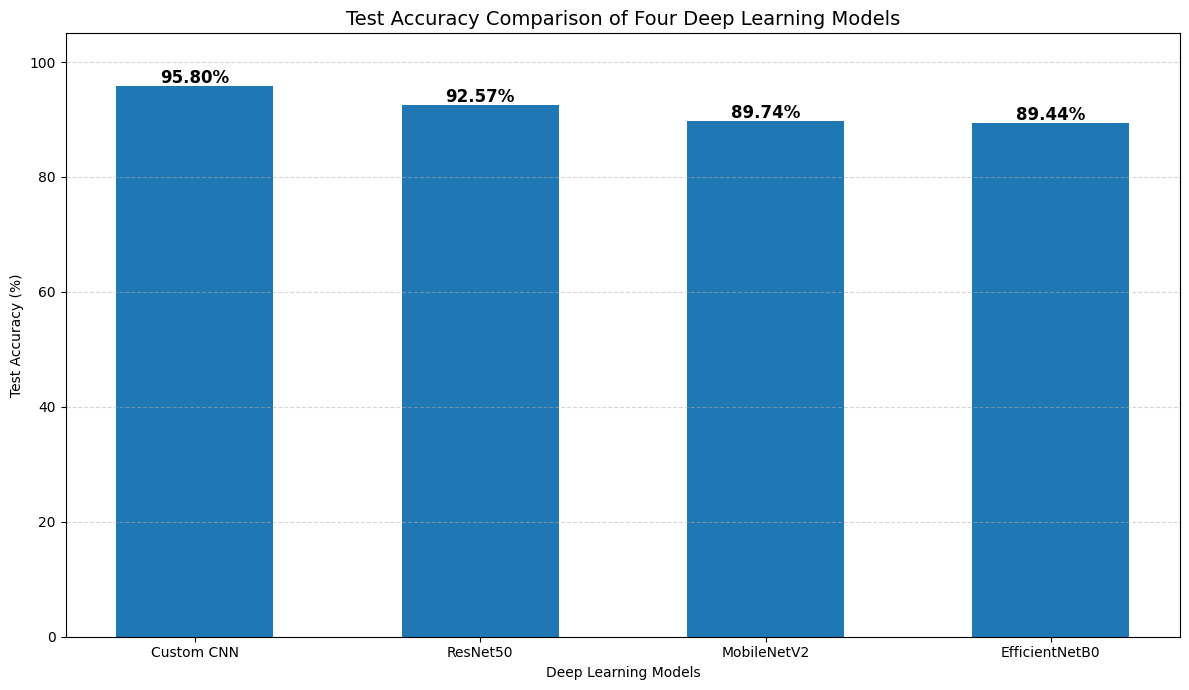

Final Accuracy Comparison Graph Saved!

STEP 40 COMPLETED SUCCESSFULLY!


In [98]:

# ==========================================
# STEP 40: FINAL ACCURACY COMPARISON GRAPH
# ==========================================

import matplotlib.pyplot as plt
import pandas as pd

# Load Final Comparison
comparison = pd.read_csv(
    f"{MODEL_DIR}/final_model_comparison.csv"
)

# Convert Accuracy to Percentage
models = comparison["Model"]
accuracies = comparison["Test Accuracy"] * 100

# Create Bar Chart
plt.figure(figsize=(12, 7))

bars = plt.bar(
    models,
    accuracies,
    width=0.55
)

# Add Accuracy Labels
for bar, value in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{value:.2f}%",
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

plt.title(
    "Test Accuracy Comparison of Four Deep Learning Models",
    fontsize=14
)

plt.xlabel("Deep Learning Models")
plt.ylabel("Test Accuracy (%)")

plt.ylim(0, 105)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()

# Save Graph
plt.savefig(
    f"{MODEL_DIR}/final_accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Final Accuracy Comparison Graph Saved!")
print("\nSTEP 40 COMPLETED SUCCESSFULLY!")


In [99]:

# ==========================================
# STEP 41: FINAL PROJECT FILE VERIFICATION
# ==========================================

import os

print("========== FINAL PROJECT FILES ==========\n")

for file in sorted(os.listdir(MODEL_DIR)):
    file_path = os.path.join(MODEL_DIR, file)

    if os.path.isfile(file_path):
        size_mb = os.path.getsize(file_path) / (1024 * 1024)
        print(f"{file} : {size_mb:.2f} MB")

print("\nTotal Files:", len(os.listdir(MODEL_DIR)))

print("\nSTEP 41 COMPLETED SUCCESSFULLY!")


========== FINAL PROJECT FILES ==========

custom_cnn_best.keras : 5.36 MB
custom_cnn_confusion_matrix.png : 0.66 MB
custom_cnn_test_results.csv : 0.00 MB
custom_cnn_training.csv : 0.00 MB
custom_cnn_training_graphs.png : 0.24 MB
efficientnetb0_best.keras : 16.60 MB
efficientnetb0_confusion_matrix.png : 0.67 MB
efficientnetb0_test_results.csv : 0.00 MB
efficientnetb0_training.csv : 0.00 MB
efficientnetb0_training_graphs.png : 0.23 MB
final_accuracy_comparison.png : 0.14 MB
final_model_comparison.csv : 0.00 MB
mobilenetv2_best.keras : 9.53 MB
mobilenetv2_confusion_matrix.png : 0.66 MB
mobilenetv2_test_results.csv : 0.00 MB
mobilenetv2_training.csv : 0.00 MB
mobilenetv2_training_graphs.png : 0.20 MB
resnet50_best.keras : 91.16 MB
resnet50_confusion_matrix.png : 0.67 MB
resnet50_test_results.csv : 0.00 MB
resnet50_training.csv : 0.00 MB
resnet50_training_graphs.png : 0.21 MB

Total Files: 22

STEP 41 COMPLETED SUCCESSFULLY!


In [100]:

# ==========================================
# STEP 42: CREATE PROJECT BACKUP ZIP
# ==========================================

import shutil
import os

backup_path = "/kaggle/working/Plant_Disease_Detection_Backup"

zip_path = shutil.make_archive(
    backup_path,
    "zip",
    MODEL_DIR
)

print("Project Backup Created Successfully!")
print("Backup Location:", zip_path)

print(
    "Backup Size:",
    round(os.path.getsize(zip_path) / (1024 * 1024), 2),
    "MB"
)

print("\nSTEP 42 COMPLETED SUCCESSFULLY!")


Project Backup Created Successfully!
Backup Location: /kaggle/working/Plant_Disease_Detection_Backup.zip
Backup Size: 114.73 MB

STEP 42 COMPLETED SUCCESSFULLY!


In [101]:
from IPython.display import FileLink, display

display(FileLink("/kaggle/working/Plant_Disease_Detection_Backup.zip"))

/kaggle/working/Plant_Disease_Detection_Backup.zip